---
title: "Shah, Kelkar, Godbole and Deckwer: the kLa recommendation"
description: "The bubble-column review recommends Akita-Yoshida as the conservative kLa estimate and kLa = b uG^0.8 with no liquid-velocity effect; the page tests both with the correlations, table and figures the review itself prints."
categories: [sec:F, struct:S1, tier:T0, data:tier4, phase:gas-liquid]
date: 2026-11-23
---

# Shah, Kelkar, Godbole and Deckwer: the kLa recommendation

**Catalog ID:** `F1.8` · **Structures:** `S1` (algebraic closure) · **Tier:** T0

The 1982 AIChE Journal review of bubble-column design parameters by Shah, Kelkar,
Godbole and Deckwer makes three statements about the volumetric mass-transfer
coefficient $k_La$ that designers still quote: the Akita-Yoshida correlation gives a
conservative estimate for less effective spargers; in general $k_La = b\,u_G^n$ with
$n \approx 0.8$ and $b$ set by the sparger and the liquid; and $k_La$ does not depend
on the liquid velocity. This page tests the three statements against what the review
itself prints: its kLa correlations (Tables 4-a.1 and 4-a.2), its holdup correlation
(Table 2.1) and its two kLa figures (Figures 6-a.1 and 6-a.2).

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.27.7"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "F1.8-shah-bubble-column-kla"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. The page is algebra: it calls no pymrm operator and solves no PDE. pymrm
# contributes pymrm.checks.find_roots, which brackets every root the page reports.
import math
import re
from dataclasses import dataclass, replace
from fractions import Fraction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pymrm.checks import find_roots
from gallery_utils import Claims, assert_check_values, cite_data, load_claims, load_data, load_meta

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
F11 = "F1.1-akita-yoshida-bubble-column"


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``; ``pctN`` shows a fraction as a
    percentage with N decimals."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        x = v[name]
        mp = re.fullmatch(r"(\+?)pct(\d+)", fmt)
        if mp:
            return f"{x * 100:{mp.group(1)}.{mp.group(2)}f} %"
        return format(x, fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))

## Background

In a bubble column the liquid-side resistance usually limits absorption, and the
design number is $k_La$, the liquid-side coefficient times the interfacial area per
volume. Shah et al. collected the $k_La$ correlations available in 1981. On p. 354
and again on p. 366 they recommend Akita and Yoshida (1973) "for a conservative
estimation of $k_La$", particularly for single or multi-orifice spargers, and note
that porous plates and two-phase nozzles give considerably higher values. Their
Table 4-a.1 fits $k_La = b\,u_G^n$ to data of Deckwer and co-workers, with $n$ from
0.78 to 0.82 and $b$ depending on the sparger and the liquid. On p. 366 they add that
"an influence of $u_L$ on $k_La$ can be neglected" (their Figure 6-a.1), so that the
correlation carries over to columns with liquid flow.

The page asks whether the review's own printed material supports these statements:
how far below the other printed correlations Akita-Yoshida sits, in units of the
printed mean errors; whether the exponent of Akita-Yoshida is near 0.8; and whether
the one data set the review prints that no correlation was fitted to (Figure
6-a.1) supports neglecting the liquid velocity. It is not a test against new data.
[F1.1](../F1.1-akita-yoshida-bubble-column/) tests Akita-Yoshida against its own
papers; [F1.3](../F1.3-wilkinson-high-pressure-holdup/) and
[F1.4](../F1.4-krishna-ellenberger-holdup/) are holdup pages.

## The published model

With $Bo = gD^2\rho_L/\sigma$, $Ga = gD^3/\nu_L^2$, $Fr = u_G/\sqrt{gD}$ and
$Sc = \nu_L/D_L$ (all dimensionless), the review prints:

**E1, holdup** (Table 2.1 no. 4, Akita-Yoshida 1973), implicit in $\varepsilon$:
$$\frac{\varepsilon}{(1-\varepsilon)^4} = C\,Bo^{1/8}Ga^{1/12}Fr,\qquad C = 0.2 .$$

**E2, Akita-Yoshida $k_La$** (Table 4-a.2 no. 1), with $\varepsilon$ from E1:
$$\frac{k_La\,D^2}{D_L} = 0.6\,Sc^{0.5}Bo^{0.62}Ga^{0.31}\varepsilon^{1.1}.$$

**E3, Hikita et al. (1981)** (Table 4-a.2 no. 4), with $f = 1$ for non-electrolytes:
$$k_La = \frac{14.9\,g f}{u_G}\left(\frac{u_G\mu_L}{\sigma}\right)^{1.76}
\left(\frac{\mu_L^4 g}{\rho_L\sigma^3}\right)^{-0.248}
\left(\frac{\mu_G}{\mu_L}\right)^{0.243}\left(\frac{\mu_L}{\rho_L D_L}\right)^{-0.604}.$$

**E4, Nakanoh-Yoshida (1980)** (Table 4-a.2 no. 3), inelastic liquids (bracket 1):
$$\frac{k_La\,D^2}{D_L} = 0.09\,Sc^{0.5}Bo^{0.75}Ga^{0.39}\,Fr .$$
The review prints the last group as $u_G/(gD)$, without the root; that group is
not dimensionless (Validation V2). The page uses $u_G/\sqrt{gD}$, the form the
same review prints in E1, and keeps the printed form as a break row.

**E5, Table 4-a.1** (eq. 6-a.2): $k_La = b\,u_G^n$ ($k_La$ in 1/s, $u_G$ in m/s), four
rows: a cross of 1 mm nozzles in a 0.2 m column and sintered plates in 0.1 to 0.15 m
columns, each with tap water and with salt solutions.

**Derived here.** Differentiating E1 and E2 at fixed properties gives the local
exponent of Akita-Yoshida,
$$\text{E6:}\quad \frac{d\ln k_La}{d\ln u_G} = \frac{1.1\,(1-\varepsilon)}{1+3\varepsilon},$$
which falls from 1.1 at $\varepsilon \to 0$. The ratio of Akita-Yoshida to $b\,u_G^n$ is
therefore largest where E6 equals $n$ (E7):
$\varepsilon^* = (1.1-n)/(1.1+3n)$ and, inverting E1 in closed form,
$u_G^* = \varepsilon^*(1-\varepsilon^*)^{-4}\sqrt{gD}/(C\,Bo^{1/8}Ga^{1/12})$.
At fixed $u_G$ the diameter exponents (E8) are $2/8 + 3/12 - 1/2 = 0$ for the holdup,
$-2 + 2(0.62) + 3(0.31)$ for E2 and $-2 + 2(0.75) + 3(0.39) - 1/2$ for E4.

| symbol | code | unit |
|---|---|---|
| $D$, $u_G$ | `D`, `uG` | m, m/s |
| $\rho_L$, $\mu_L$, $\sigma$, $D_L$, $\mu_G$ | `L.rho`, `L.mu`, `L.sigma`, `L.DL`, `L.muG` | SI |
| $\varepsilon$ | `holdup_ay(...)` | - |
| E2, E3, E4, E5 | `kla_ay`, `kla_hikita`, `kla_ny`, `kla_row` | 1/s |
| E6 | `slope_e6(eps, K)` | - |

## Parameters and assumptions

Every constant and stated range is a row of `shah-1982-printed-numbers.csv`, read from
the page images and kept as printed; the page loads them into the one dictionary `K`
that every function takes, so a break row per constant is one call. The liquid is
water at 20 C from F1.1's property table (the `water_20` row); the review prints no
water properties. Air viscosity $\mu_G = 1.81\times10^{-5}$ Pa s (the usual handbook value for
air at 20 C and 1 atm, not checked here against a specific table) and $g = 9.81$
m/s² are page inputs; R2 gives the effect of $\mu_G$ on Hikita's maximum ratio over a
bracket of air viscosities around the page value. The test condition of the check values is $D = 0.15$ m,
$u_G = 0.05$ m/s.

Ambiguities in the printed text, recorded and not resolved unless stated:

- **A1** E4's group $u_G/(gD)$ lacks the root (fixed here, Validation V2).
- **A2** E4's elasticity bracket places $m$ unclearly; irrelevant for water ($C = 0$).
- **A3** Table 4-a.2 no. 3 lists water-air but states $\mu_L$ 0.005 to 0.06 Pa s;
  water is outside, so E4 is shown and left out of every count.
- **A4** The Akita-Yoshida liquid-velocity range is 0 to 0.044 m/s in Table 2.1 and
  0.0 to 0.44 m/s in Table 4-a.2 (heights 1.26 to 3.5 m against 0.126 to 0.35 m). One
  is wrong by a factor of ten; the review cannot decide which, and the page uses both.
- **A5** Hikita's $D_L$ range "4.6-26.0 m²/s" lacks a factor $10^{-9}$.
- **A6** "Sintered plates (150 m)" lost its micrometre sign, and the Table 4-a.1
  "Mean Error, %" is not defined; the page compares with it as a relative error.
- **A7** The recommendation cites Akita-Yoshida 1973 (p. 354, Table 4-a.2) and 1974
  (p. 368, the Figure 6-a.2 caption, whose line label reads 1973); the page uses the
  1973 form of Table 4-a.2.
- **A8** The text of pp. 365 and 366 calls Table 4-a.1 "Table 6-a.1" and "Table 4-2.1".
- **A9** The basis of the nozzle row is $u_L$ = 0.01 to 0.03 m/s in the Figure 6-a.1
  label and 0.007 to 0.03 m/s in the text.

In [3]:
PN = load_data("shah-1982-printed-numbers.csv", page=PAGE, dtype=str)
K = {r.name: float(Fraction(r.printed)) for r in PN.itertuples()}
PRINTED = dict(zip(PN.name, PN.printed))
display(PN.set_index("name"))
ROWS = ("noz_tap", "noz_salt", "sin_tap", "sin_salt")
MU_AIR = 1.81e-5       # Pa s, air at 20 C and 1 atm, the usual handbook value (not checked against a specific table); the review prints none; R2 shows its effect
MU_AIR_BRACKET = (1.7e-5, 1.9e-5)  # Pa s, air from 0 to 40 C: the sensitivity of Hikita's ratio in R2
UL_PAIR_TOL = 0.06     # Fig 6-a.1 pairs: markers of two liquid velocities match within this fraction in uG
D_SCAN = (0.01, 5.0)   # m, physical range of the column diameter for the A-Y/Hikita crossing
G = 9.81               # m/s2
D_T, UG_T = 0.15, 0.05  # m, m/s: the test condition of the check values

,printed,where,meaning
name,,,
ay_C,0.2,Table 2.1 no. 4 (p. 360),A-Y holdup: eps/(1-eps)^4 = C Bo^(1/8) Ga^(1/1...
ay_C_electrolyte,0.25,Table 2.1 no. 4 (p. 360),A-Y holdup coefficient for electrolytes
ay_holdup_power,4,Table 2.1 no. 4 (p. 360),power on (1 - eps)
ay_a_Bo,1/8,Table 2.1 no. 4 (p. 360),holdup exponent on Bo
ay_b_Ga,1/12,Table 2.1 no. 4 (p. 360),holdup exponent on Ga
...,...,...,...
n_max_kastanek,0.82,text p. 365,upper end of the exponent n found by Kastanek ...
f6a1_D,0.14,Fig 6-a.1 (p. 366),column diameter of the Fig 6-a.1 data (m); rin...
f6a1_Ht,2.65,Fig 6-a.1 (p. 366),height of the Fig 6-a.1 column (m)


## The data

- **Water at 20 C**: the `water_20` row of F1.1's
  `akita-yoshida-1974-table2-properties.csv`, borrowed with `load_data(..., page=F1.1)`.
  F1.1 recomputes the 1973 Bond, Galilei and Schmidt numbers from this table and
  finds the two tables consistent to the worst difference printed below (its claims,
  read with `load_claims`). That finding concerns the rows this page uses only as a
  bound on how well the property values are known; nothing on F1.1 flags `water_20`.
  F1.1's printed constants of Akita and Yoshida are borrowed too, for Validation V1.
- **Figure 6-a.1** (p. 366): $k_La$ against $u_G$ in a 0.14 m column with a ring
  sparger at liquid velocities 0.054, 0.076 and 0.108 m/s, 21 markers and the dashed
  line of the nozzle row, digitised from the native 300 ppi scan.
- **Figure 6-a.2** (p. 366): measured $k_La$ of four authors against the
  Akita-Yoshida group with measured holdup, 24 markers (one partly hidden, shape
  undecidable, labelled `unassigned` and used only pooled) and the drawn line.
- The printed constants above.

Table 4-a.1 and Figure 6-a.2 are fitted or selected data: the first is the basis of
the $b\,u_G^n$ rows, the second is shown by the review to support Akita-Yoshida. Only
Figure 6-a.1 is held out: none of it lies inside the basis of the nozzle row (0.2 m
column, nozzle cross, $u_L$ up to 0.03 m/s).

In [4]:
WATER = load_data("akita-yoshida-1974-table2-properties.csv", page=F11).set_index("key").loc["water_20"]
F11PN = load_data("akita-yoshida-printed-numbers.csv", page=F11, dtype=str)
F6A1 = load_data("shah-1982-fig6a1.csv", page=PAGE, keep_default_na=False)
F6A2 = load_data("shah-1982-fig6a2.csv", page=PAGE, keep_default_na=False)
for name in ("shah-1982-printed-numbers", "shah-1982-fig6a1", "shah-1982-fig6a2"):
    print(cite_data(load_meta(name + ".csv", page=PAGE)))
print(cite_data(load_meta("akita-yoshida-1974-table2-properties.csv", page=F11)))
F11C = load_claims(F11)
say("F1.1 on its property table: the 1973 groups recomputed from it differ from the "
    "printed ones by at most <<w:pct2>> over <<n:d>> entries.",
    w=F11C["grp_worst_rel_dev"], n=int(F11C["grp_entries"]))
display(WATER.to_frame().T)


@dataclass(frozen=True)
class Liquid:
    """Liquid and gas properties in one consistent unit system."""
    rho: float
    mu: float
    sigma: float
    DL: float
    muG: float

    def cgs(self):
        """The same liquid in cm-g-s units."""
        return Liquid(self.rho * 1e-3, self.mu * 10, self.sigma * 1e3, self.DL * 1e4, self.muG * 10)


@dataclass(frozen=True)
class Data:
    """The page's inputs besides the printed constants."""
    L: Liquid
    f6a1: pd.DataFrame
    f6a2: pd.DataFrame
    f11pn: pd.DataFrame
    g: float = G
    ay_fr_root: bool = True    # E1 Froude group uG/sqrt(gD) as printed
    ny_fr_root: bool = True    # E4 Froude group restored to uG/sqrt(gD) (A1)
    D_T: float = D_T
    uG_T: float = UG_T


WATER20 = Liquid(WATER.density_g_cm3 * 1e3, WATER.viscosity_cP * 1e-3,
                 WATER.surface_tension_dyn_cm * 1e-3, WATER["diffusivity_O2_1e-5_cm2_s"] * 1e-9, MU_AIR)
C = Data(WATER20, F6A1, F6A2, F11PN)

Shah, Y. T.; Kelkar, B. G.; Godbole, S. P.; Deckwer, W.-D. (1982) — AIChE Journal 28(3) 353-379 — doi:10.1002/aic.690280302 — page-image transcription
Shah, Y. T.; Kelkar, B. G.; Godbole, S. P.; Deckwer, W.-D. (1982) — AIChE Journal 28(3) 353-379 — doi:10.1002/aic.690280302 — digitised from Figure 6-a.1, journal page 366
Shah, Y. T.; Kelkar, B. G.; Godbole, S. P.; Deckwer, W.-D. (1982) — AIChE Journal 28(3) 353-379 — doi:10.1002/aic.690280302 — digitised from Figure 6-a.2, journal page 366
Akita, K.; Yoshida, F. (1974) — Industrial & Engineering Chemistry Process Design and Development 13(1) 84-91 — doi:10.1021/i260049a016 — page-image transcription


F1.1 on its property table: the 1973 groups recomputed from it differ from the printed ones by at most 0.72 % over 32 entries.

,liquid,temp_C,density_g_cm3,viscosity_cP,surface_tension_dyn_cm,diffusivity_O2_1e-5_cm2_s
water_20,Water,20,0.9982,1.005,72.8,2.1


## PyMRM implementation

There is no pymrm model on this page: the correlations are closed forms. The
functions take SI arguments (or cm-g-s, for Validation V2), the dictionary `K` and the
data container. The holdup of E1 is implicit and is solved with
`pymrm.checks.find_roots`, which scans the whole physical range $(10^{-9}, 0.99)$ and
refines every sign change; the page raises unless exactly one root is found. The
maxima of E7 are found twice: in closed form, and as the root of E6 minus $n$ with
`find_roots` on the stated $u_G$ window.

In [5]:
def groups(D, L, g):
    """Bond, Galilei and Schmidt numbers."""
    nu = L.mu / L.rho
    return g * D**2 * L.rho / L.sigma, g * D**3 / nu**2, nu / L.DL


def froude(uG, D, g, root):
    """uG/sqrt(gD), or the printed uG/(gD) of E4 when ``root`` is False."""
    return uG / np.sqrt(g * D) if root else uG / (g * D)


def holdup_rhs(D, L, g, K):
    """C Bo^(1/8) Ga^(1/12): the right side of E1 without the Froude number."""
    Bo, Ga, _ = groups(D, L, g)
    return K["ay_C"] * Bo**K["ay_a_Bo"] * Ga**K["ay_b_Ga"]


def holdup_ay(uG, D, L, g, K, C):
    """E1: the one root of eps/(1-eps)^4 = C Bo^(1/8) Ga^(1/12) Fr on (1e-9, 0.99)."""
    rhs = holdup_rhs(D, L, g, K) * froude(uG, D, g, C.ay_fr_root)
    res = find_roots(lambda e: e / (1 - e)**K["ay_holdup_power"] - rhs, 1e-9, 0.99,
                     n_scan=200, log=True, xtol=1e-15)
    if len(res["roots"]) != 1:
        raise ValueError(f"E1 has {len(res['roots'])} roots: {res['message']}")
    return res["roots"][0]


def kla_ay(uG, D, L, g, K, C):
    """E2, with the holdup of E1 (1/s)."""
    Bo, Ga, Sc = groups(D, L, g)
    eps = holdup_ay(uG, D, L, g, K, C)
    return (K["ay_c2"] * L.DL / D**2 * Sc**K["ay_sc_exp"] * Bo**K["ay_p_Bo"]
            * Ga**K["ay_q_Ga"] * eps**K["ay_eps_exp"])


def kla_hikita(uG, L, g, K):
    """E3, Hikita et al. (1981), non-electrolytes (1/s)."""
    return (K["hik_c"] * g * K["hik_f"] / uG * (uG * L.mu / L.sigma)**K["hik_e1"]
            * (L.mu**4 * g / (L.rho * L.sigma**3))**K["hik_e2"]
            * (L.muG / L.mu)**K["hik_e3"] * (L.mu / (L.rho * L.DL))**K["hik_e4"])


def kla_ny(uG, D, L, g, K, C):
    """E4, Nakanoh-Yoshida (1980), inelastic liquid (1/s); Froude form per ``C``."""
    Bo, Ga, Sc = groups(D, L, g)
    return (K["ny_c"] * L.DL / D**2 * Sc**K["ny_sc_exp"] * Bo**K["ny_p_Bo"]
            * Ga**K["ny_q_Ga"] * froude(uG, D, g, C.ny_fr_root)**K["ny_fr_exp"])


def kla_row(uG, K, row):
    """E5, a row of Table 4-a.1: b uG^n (1/s, uG in m/s)."""
    return K[row + "_b"] * uG**K[row + "_n"]


def slope_e6(eps, K):
    """E6: d ln kLa_AY / d ln uG = 1.1 (1 - eps)/(1 + 3 eps), from E1 and E2."""
    return K["ay_eps_exp"] * (1 - eps) / (1 + (K["ay_holdup_power"] - 1) * eps)


def e7_closed(n, D, L, g, K, C):
    """E7 in closed form: (eps*, uG*) where E6 = n."""
    e = (K["ay_eps_exp"] - n) / (K["ay_eps_exp"] + (K["ay_holdup_power"] - 1) * n)
    lhs = e / (1 - e)**K["ay_holdup_power"]
    scale = np.sqrt(g * D) if C.ay_fr_root else g * D
    return e, lhs / holdup_rhs(D, L, g, K) * scale


def e7_roots(n, lo, hi, D, L, g, K, C):
    """Every uG on [lo, hi] where E6 = n, by find_roots (0 or 1 roots)."""
    f = lambda u: slope_e6(holdup_ay(u, D, L, g, K, C), K) - n
    res = find_roots(f, lo, hi, n_scan=60, log=True)
    if len(res["roots"]) > 1:
        raise ValueError(f"E6 = {n}: {len(res['roots'])} roots on [{lo}, {hi}]")
    return res["roots"]


def one_root(n, lo, hi, D, L, g, K, C):
    """The single uG on [lo, hi] where E6 = n; raises otherwise."""
    r = e7_roots(n, lo, hi, D, L, g, K, C)
    if len(r) != 1:
        raise ValueError(f"E6 = {n}: no root on [{lo}, {hi}]")
    return r[0]


def dlog(f, x, h=1e-4):
    """Central difference of ln f against ln x, step h in ln x."""
    return (np.log(f(x * np.exp(h))) - np.log(f(x * np.exp(-h)))) / (2 * h)


def stop_rules(kla=(), eps=(), ratio=()):
    """The plan's unit guards: raise outside the physical windows."""
    for v in kla:
        if not 1e-3 <= v <= 0.3:
            raise ValueError(f"kLa {v:g} 1/s outside 1e-3 to 0.3")
    for v in eps:
        if not 0 < v < 0.5:
            raise ValueError(f"holdup {v:g} outside (0, 0.5)")
    for v in ratio:
        if not 0.3 <= v <= 5:
            raise ValueError(f"ratio to A-Y {v:g} outside 0.3 to 5")

### The check values

`data/check_values.csv` holds the same quantities computed by a second route (a
separate script in plain Python, no pymrm and no page code) at the test condition.
The page's functions must reproduce every row before any number is registered.

In [6]:
def check_computed(K, C):
    """The page's value for every row of data/check_values.csv."""
    L, g, D, u = C.L, C.g, C.D_T, C.uG_T
    Bo, Ga, Sc = groups(D, L, g)
    ay = kla_ay(u, D, L, g, K, C)
    pr = replace(C, ny_fr_root=False)
    out = {"nu_L_m2_s": L.mu / L.rho, "N_Bo": Bo, "N_Ga": Ga, "N_Fr": froude(u, D, g, True), "N_Sc": Sc,
           "eps_AY_E1": holdup_ay(u, D, L, g, K, C), "kLa_AY_E2_1_s": ay,
           "kLa_Hikita_E3_1_s": kla_hikita(u, L, g, K), "kLa_NY_E4_restored_1_s": kla_ny(u, D, L, g, K, C),
           "kLa_NY_E4_printed_SI_numeric": kla_ny(u, D, L, g, K, pr)}
    for r, nm in zip(ROWS, ("nozzle_tap", "nozzle_salt", "sintered_tap", "sintered_salt")):
        out[f"kLa_row_{nm}_1_s"] = kla_row(u, K, r)
    out |= {"ratio_Hikita_over_AY": kla_hikita(u, L, g, K) / ay, "ratio_NY_over_AY": kla_ny(u, D, L, g, K, C) / ay,
            "ratio_nozzle_tap_over_AY": kla_row(u, K, "noz_tap") / ay,
            "ratio_sintered_tap_over_AY": kla_row(u, K, "sin_tap") / ay,
            "ratio_AY_D0p2_over_nozzle_tap": kla_ay(u, 0.2, L, g, K, C) / kla_row(u, K, "noz_tap"),
            "slope_AY_E6_at_T": slope_e6(holdup_ay(u, D, L, g, K, C), K),
            "slope_AY_fd_at_T": dlog(lambda x: kla_ay(x, D, L, g, K, C), u),
            "slope_AY_limit_uG_to_0": slope_e6(0.0, K),
            "slope_Hikita_fd": dlog(lambda x: kla_hikita(x, L, g, K), u)}
    return out | check_extrema(K, C)


def check_extrema(K, C):
    """Check-value rows of E7, the window ends, the exponents and the dimensions."""
    L, g = C.L, C.g
    out = {}
    for tag, n, D, lo, hi, den in (("nozzle", K["noz_tap_n"], 0.2, 0.003, 0.08, lambda u: kla_row(u, K, "noz_tap")),
                                   ("hikita", K["hik_e1"] - 1, 0.15, 0.042, 0.38, lambda u: kla_hikita(u, L, g, K))):
        e, u = e7_closed(n, D, L, g, K, C)
        lab = f"{tag}_n{str(round(n, 2)).replace('.', 'p')}_D{str(D).replace('.', 'p')}"
        out[f"eps_star_{lab}"], out[f"uG_star_closed_{lab}"] = e, u
        out[f"uG_star_bisect_{lab}"] = one_root(n, lo, hi, D, L, g, K, C)
        what = "nozzle_tap" if tag == "nozzle" else "Hikita"
        out[f"max_ratio_AY_over_{what}_{lab}"] = kla_ay(u, D, L, g, K, C) / den(u)
    ayn = lambda u, D=0.2: kla_ay(u, D, L, g, K, C) / kla_row(u, K, "noz_tap")
    for u in (0.003, 0.08):
        out[f"ratio_AY_over_nozzle_tap_D0p2_uG{u}"] = ayn(u)
    f = lambda u: kla_ay(u, 0.2, L, g, K, C)
    out["secant_exponent_AY_D0p2_0p003_to_0p08"] = math.log(f(0.08) / f(0.003)) / math.log(0.08 / 0.003)
    out["slope_AY_D0p2_at_0p003"] = slope_e6(holdup_ay(0.003, 0.2, L, g, K, C), K)
    out["slope_AY_D0p2_at_0p08"] = slope_e6(holdup_ay(0.08, 0.2, L, g, K, C), K)
    for u in (0.042, 0.08, 0.38):
        out[f"ratio_AY_over_Hikita_D0p15_uG{u}"] = kla_ay(u, 0.15, L, g, K, C) / kla_hikita(u, L, g, K)
    for r, a, b in (("nozzle", 0.004, 0.08), ("sintered", 0.004, 0.04)):
        p = "noz" if r == "nozzle" else "sin"
        for u in (a, b):
            out[f"salt_over_tap_{r}_uG{u}"] = kla_row(u, K, p + "_salt") / kla_row(u, K, p + "_tap")
    return out | check_dimensions(K, C)


def check_dimensions(K, C):
    """Check-value rows of E8, the D range end, the unit systems and F1.1."""
    L, g, D, u = C.L, C.g, C.D_T, C.uG_T
    pr = replace(C, ny_fr_root=False)
    out = {"D_exp_kLa_AY": dlog(lambda d: kla_ay(u, d, L, g, K, C), D),
           "D_exp_kLa_NY_restored": dlog(lambda d: kla_ny(u, d, L, g, K, C), D),
           "D_exp_kLa_NY_printed": dlog(lambda d: kla_ny(u, d, L, g, K, pr), D),
           "AY_D0p152_over_D0p15": kla_ay(u, 0.152, L, g, K, C) / kla_ay(u, 0.15, L, g, K, C)}
    Lc, gc = L.cgs(), g * 100
    out["dimcheck_NY_restored_cgs_over_SI"] = kla_ny(u * 100, D * 100, Lc, gc, K, C) / kla_ny(u, D, L, g, K, C)
    out["dimcheck_NY_printed_cgs_over_SI"] = kla_ny(u * 100, D * 100, Lc, gc, K, pr) / kla_ny(u, D, L, g, K, pr)
    out["dimcheck_Hikita_cgs_over_SI"] = kla_hikita(u * 100, Lc, gc, K) / kla_hikita(u, L, g, K)
    out["dimcheck_AY_groups_cgs_over_SI_Bo"] = groups(D * 100, Lc, gc)[0] / groups(D, L, g)[0]
    L11 = replace(L, mu=1.005e-6 * L.rho)
    out["F1p1_eps_at_nu_1p005e-6"] = holdup_ay(u, D, L11, g, K, C)
    out["F1p1_kLa_at_nu_1p005e-6"] = kla_ay(u, D, L11, g, K, C)
    return out


CHECK_DEV = assert_check_values(check_computed(K, C), page=PAGE)

check values: 53 of 53 agree, worst relative 1.4e-11


### The study

`study(K, C)` computes every number the page reports from the printed constants and
the data, in one pass; the break table reruns it with one defect at a time.

In [7]:
def r1_correlations(K, C):
    """R1: the five air-water correlations at T and their minimum ratio to A-Y."""
    L, g, D, u = C.L, C.g, C.D_T, C.uG_T
    ay = kla_ay(u, D, L, g, K, C)
    others = {"hikita": (lambda x: kla_hikita(x, L, g, K), K["hik_e1"] - 1, K["hik_uG_min"], K["hik_uG_max"]),
              "ny": (lambda x: kla_ny(x, D, L, g, K, C), K["ny_fr_exp"], K["ay_uG_min"], K["ny_uG_max"]),
              "noz_tap": (lambda x: kla_row(x, K, "noz_tap"), K["noz_tap_n"], K["noz_tap_uG_min"], K["noz_tap_uG_max"]),
              "sin_tap": (lambda x: kla_row(x, K, "sin_tap"), K["sin_tap_n"], K["sin_tap_uG_min"], K["sin_tap_uG_max"])}
    M = {"kla_ay_T": ay, "eps_ay_T": holdup_ay(u, D, L, g, K, C)}
    for name, (f, n, lo, hi) in others.items():
        lo, hi = max(lo, K["ay_uG_min"]), min(hi, K["ay_uG_max"])
        M[f"ratio_{name}_over_ay_T"] = f(u) / ay
        M[f"kla_{name}_T"] = f(u)
        cand = [lo, hi] + e7_roots(n, lo, hi, D, L, g, K, C)
        r = [f(x) / kla_ay(x, D, L, g, K, C) for x in cand]
        M[f"min_ratio_{name}_over_ay"] = min(r)
        stop_rules(ratio=[min(r), f(u) / ay])  # the reported ratios; window ends may exceed 5 (sintered at 0.003 m/s)
    counted = [M[f"min_ratio_{k}_over_ay"] for k in ("hikita", "noz_tap", "sin_tap")]
    M["_counted"] = counted
    M["mu_water_over_ny_muL_min"] = L.mu / K["ny_muL_min"]
    stop_rules(kla=[ay] + [f(u) for f, *_ in others.values()], eps=[M["eps_ay_T"]])
    return M


def window_max(num, den, n, lo, hi, D, L, g, K, C):
    """Maximum of num/den over [lo, hi]: the window ends and the interior roots of E6 = n.

    d ln(ratio)/d ln uG = E6 - n, so the maximum is at the interior root when there is
    one (0 or 1) and at a window end otherwise. Returns the maximum and the roots."""
    roots = e7_roots(n, lo, hi, D, L, g, K, C)
    return max(num(x) / den(x) for x in [lo, hi] + roots), roots


def hik_max_ratio_closed(D, K, C):
    """Maximum over Hikita's window of A-Y/Hikita at diameter D: the closed-form E7 point
    when it lies inside the window, else a window end (a second route to window_max)."""
    L, g = C.L, C.g
    n, lo, hi = K["hik_e1"] - 1, K["hik_uG_min"], K["hik_uG_max"]
    cand = [lo, hi]
    if n < K["ay_eps_exp"]:
        us = e7_closed(n, D, L, g, K, C)[1]
        cand += [us] if lo < us < hi else []
    return max(kla_ay(u, D, L, g, K, C) / kla_hikita(u, L, g, K) for u in cand)


def r2_conservative(K, C):
    """R2 and R3: A-Y against the nozzle row (D 0.2 m) and Hikita (D 0.15 m)."""
    L, g = C.L, C.g
    M = {}
    lo, hi, D, n = max(K["noz_tap_uG_min"], K["ay_uG_min"]), K["noz_tap_uG_max"], K["noz_D"], K["noz_tap_n"]
    row = lambda u: kla_row(u, K, "noz_tap")
    ay = lambda u, D=D: kla_ay(u, D, L, g, K, C)
    M["noz_max_ratio"], roots = window_max(ay, row, n, lo, hi, D, L, g, K, C)
    if roots:   # the E7 point and the root gap exist only with an interior maximum
        e, us = e7_closed(n, D, L, g, K, C)
        M["noz_eps_star"], M["noz_uG_star"] = e, us
        M["noz_uG_star_root_gap"] = abs(roots[0] / us - 1)
    M["noz_ratio_lo"], M["noz_ratio_hi"] = (ay(u) / row(u) for u in (lo, hi))
    M["noz_gap_over_err"] = (1 - M["noz_max_ratio"]) / (K["noz_tap_err"] / 100)
    M["noz_gap_lo_over_err"] = (1 - M["noz_ratio_lo"]) / (K["noz_tap_err"] / 100)
    hlo, hhi, Dh, nh = K["hik_uG_min"], K["hik_uG_max"], D_T, K["hik_e1"] - 1
    hik = lambda u: kla_hikita(u, L, g, K)
    M["hik_max_ratio"], roots = window_max(lambda u: kla_ay(u, Dh, L, g, K, C), hik, nh, hlo, hhi, Dh, L, g, K, C)
    if roots:
        eh, uh = e7_closed(nh, Dh, L, g, K, C)
        M["hik_uG_star"] = uh
        M["hik_uG_star_root_gap"] = abs(roots[0] / uh - 1)
    M["hik_ratio_lo"], M["hik_ratio_hi"] = (kla_ay(u, Dh, L, g, K, C) / hik(u) for u in (hlo, hhi))
    for tag, mu in zip(("lo", "hi"), MU_AIR_BRACKET):   # the air viscosity is a page input
        Lm = replace(L, muG=mu)
        M[f"hik_max_ratio_muG_{tag}"] = window_max(lambda u: kla_ay(u, Dh, L, g, K, C),
                                                   lambda u: kla_hikita(u, Lm, g, K), nh, hlo, hhi, Dh, L, g, K, C)[0]
    # Akita-Yoshida has a diameter and Hikita none: the maximum ratio at other diameters
    for tag, Dx in (("hik_Dmin", K["hik_D_min"]), ("hik_Dmax", K["hik_D_max"]), ("ay_Dmax", K["ay_D_max"])):
        M[f"hik_max_ratio_{tag}"] = window_max(lambda u: kla_ay(u, Dx, L, g, K, C), hik, nh, hlo, hhi, Dx, L, g, K, C)[0]
    roots = find_roots(lambda Dx: hik_max_ratio_closed(Dx, K, C) - 1, *D_SCAN, n_scan=80, log=True, xtol=1e-12)["roots"]
    if len(roots) == 1:   # the study records the crossing only when it is unique on the whole range
        M["hik_cross_D"] = roots[0]
        gap = window_max(lambda u: kla_ay(u, roots[0], L, g, K, C), hik, nh, hlo, hhi, roots[0], L, g, K, C)[0] - 1
        if abs(gap) > 1e-6:
            raise ValueError(f"the crossing diameter fails the maximum found by roots: {gap:.2e}")
    f = lambda u: kla_ay(u, D, L, g, K, C)
    M["secant_exp_noz_window"] = math.log(f(hi) / f(lo)) / math.log(hi / lo)
    M["e6_noz_lo"] = slope_e6(holdup_ay(lo, D, L, g, K, C), K)
    M["e6_noz_hi"] = slope_e6(holdup_ay(hi, D, L, g, K, C), K)
    M["e6_T"] = slope_e6(holdup_ay(C.uG_T, C.D_T, L, g, K, C), K)
    M["secant_minus_n_noz"] = M["secant_exp_noz_window"] - n
    roots = e7_roots(0.8, lo, hi, D, L, g, K, C)
    if len(roots) == 1:
        M["uG_e6_eq_0p8"] = roots[0]
    stop_rules(ratio=[M["noz_max_ratio"], M["noz_ratio_lo"], M["noz_ratio_hi"], M["hik_max_ratio"]])
    return M


def r6_constants(K):
    """R6: ratios of printed constants within Table 4-a.1."""
    M = {"sin_over_noz_tap": kla_row(0.05, K, "sin_tap") / kla_row(0.05, K, "noz_tap")}
    for p, a, b in (("noz", K["noz_salt_uG_min"], K["noz_salt_uG_max"]),
                    ("sin", K["sin_salt_uG_min"], K["sin_salt_uG_max"])):
        M[f"salt_over_tap_{p}_lo"] = kla_row(a, K, p + "_salt") / kla_row(a, K, p + "_tap")
        M[f"salt_over_tap_{p}_hi"] = kla_row(b, K, p + "_salt") / kla_row(b, K, p + "_tap")
    return M

In [8]:
def mean_se(x):
    """Mean and its standard error."""
    x = np.asarray(x, float)
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x))


def ols(x, y):
    """Slope of y on x and its standard error."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    b, a = np.polyfit(x, y, 1)
    r = y - (a + b * x)
    return b, np.sqrt(r @ r / (len(x) - 2) / ((x - x.mean()) @ (x - x.mean())))


def ul_effect(df, tag):
    """Per-series mean log ratio, the uL 0.108 - 0.054 difference (Welch) and the slope on uL."""
    M = {}
    g_ = {u: d.lr.to_numpy() for u, d in df.groupby("uL_m_s")}
    lo_u, hi_u = min(g_), max(g_)
    for u, v in g_.items():
        M[f"{tag}_mean_lr_uL{u}"], M[f"{tag}_se_lr_uL{u}"] = mean_se(v)
    a, b = g_[hi_u], g_[lo_u]
    M[f"{tag}_diff"] = a.mean() - b.mean()
    M[f"{tag}_diff_se"] = math.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    M[f"{tag}_diff_t"] = M[f"{tag}_diff"] / M[f"{tag}_diff_se"]
    M[f"{tag}_slope"], M[f"{tag}_slope_se"] = ols(df.uL_m_s, df.lr)
    return M


def ul_pairs(df, tol):
    """Highest minus lowest liquid velocity at matched gas velocity: each marker of the
    highest-uL series is paired with the nearest-uG marker of the lowest-uL series if that
    lies within ``tol`` (fraction of uG), each used once; mean, standard error and t of
    the paired differences in log ratio to the drawn line."""
    hi_u, lo_u = df.uL_m_s.max(), df.uL_m_s.min()
    A, B = df[df.uL_m_s == hi_u], df[df.uL_m_s == lo_u]
    dist = np.abs(B.uG_m_s.to_numpy()[None, :] / A.uG_m_s.to_numpy()[:, None] - 1)
    j = dist.argmin(axis=1)    # the nearest partner of each marker, accepted within tol
    ok = dist[np.arange(len(A)), j] <= tol
    if len(set(j[ok])) != ok.sum():
        raise ValueError("a marker is paired twice")
    m, se = mean_se(A.lr.to_numpy()[ok] - B.lr.to_numpy()[j[ok]])
    return {"ul_pair_diff": m, "ul_pair_se": se, "ul_pair_t": m / se, "ul_pair_n": int(ok.sum()),
            "ul_pair_n__margin": float(np.abs(dist - tol).min())}


def r4_fig6a1(K, C):
    """R4: Figure 6-a.1 against the drawn row line and against A-Y at D 0.14 m."""
    L, g, D = C.L, C.g, K["f6a1_D"]
    d = C.f6a1[C.f6a1.kind == "marker"].copy()
    d["uL_m_s"] = d.uL_m_s.astype(float)
    row = kla_row(d.uG_m_s.to_numpy(), K, "noz_tap")
    ay = np.array([kla_ay(u, D, L, g, K, C) for u in d.uG_m_s])
    q_row, q_ay = d.kLa_1_s.to_numpy() / row, d.kLa_1_s.to_numpy() / ay
    M = {"f1_n": len(d), "f1_geo_row": np.exp(np.log(q_row).mean()),
         "f1_mad_row": np.abs(q_row - 1).mean(), "f1_geo_ay": np.exp(np.log(q_ay).mean()),
         "f1_mad_ay": np.abs(q_ay - 1).mean()}
    M["f1_mad_row_over_err"] = M["f1_mad_row"] / (K["noz_tap_err"] / 100)
    M["_q_ay"], M["_q_row"] = q_ay, q_row
    M["f1_ay_D_range_effect"] = kla_ay(0.05, K["ay_D_min"], L, g, K, C) / kla_ay(0.05, D, L, g, K, C)
    M["_uL"] = d.uL_m_s.to_numpy()
    d["lr"] = np.log(q_row)
    M |= ul_effect(d, "ul_all")
    M |= ul_pairs(d, UL_PAIR_TOL)
    M |= ul_effect(d[d.uG_m_s <= K["noz_tap_uG_max"]], "ul_le08")
    first = d.groupby("uL_m_s").uG_m_s.transform("min") == d.uG_m_s
    M |= ul_effect(d[~first], "ul_nofirst")
    M["f1_n_gt_08"] = int((d.uG_m_s > K["noz_tap_uG_max"]).sum())
    stop_rules(kla=d.kLa_1_s.to_numpy()[d.uG_m_s.to_numpy() > 0.02], ratio=q_ay)
    return M


def r5_fig6a2(K, C, ratio_lo, ratio_hi):
    """R5: Figure 6-a.2 markers over the line c2 x, by author, and the pooled sign test."""
    d = C.f6a2[C.f6a2.kind == "marker"]
    q = d.kLa_1_s.to_numpy() / (K["ay_c2"] * d.x_group.to_numpy())
    M = {"f2_n": len(d)}
    for m in ("triangle", "square", "diamond", "circle"):
        lq = np.log(q[d.marker.to_numpy() == m])
        M[f"f2_{m}_n"] = len(lq)
        M[f"f2_{m}_geo"] = math.exp(lq.mean())
        M[f"f2_{m}_se_log"] = lq.std(ddof=1) / math.sqrt(len(lq))
        M[f"_f2_{m}_q"] = np.exp(lq)
    M["_f2_q"] = q
    k, n = int((q > 1).sum()), len(q)
    M["f2_n_above"] = k
    sign_p = lambda j: min(1.0, 2 * sum(math.comb(n, i) for i in range(max(j, n - j), n + 1)) / 2**n)
    M["f2_sign_p"] = sign_p(k)
    M["f2_sign_p_one_fewer"], M["f2_sign_p_one_more"] = sign_p(k - 1), sign_p(k + 1)
    M["f2_nearest_marker_dev"] = float(np.abs(q - 1).min())
    # Holdup ratio that would reconcile the Deckwer squares (D 0.20 m) with R2's
    # A-Y/nozzle ratio at D 0.2: (1/(ratio x geo))^(1/1.1).
    gd = M["f2_square_geo"]
    M["f2_holdup_ratio_at_max"] = (1 / (ratio_hi * gd))**(1 / K["ay_eps_exp"])
    M["f2_holdup_ratio_at_lo"] = (1 / (ratio_lo * gd))**(1 / K["ay_eps_exp"])
    return M


def v_checks(K, C):
    """V1 to V4: reprint fidelity, dimensions, analytic limits and the digitised lines."""
    L, g, D, u = C.L, C.g, C.D_T, C.uG_T
    f11 = {r.name: Fraction(r.printed) for r in C.f11pn.itertuples()}
    pairs = {"ay_C": "c1", "ay_C_electrolyte": "c1_electrolyte", "ay_a_Bo": "a_Bo", "ay_b_Ga": "b_Ga",
             "ay_holdup_power": "holdup_power", "ay_c2": "c2", "ay_sc_exp": "sc_exp", "ay_p_Bo": "p_Bo",
             "ay_q_Ga": "q_Ga", "ay_eps_exp": "eps_exp"}
    M = {"v1_pairs": len(pairs),
         "v1_agree": sum(Fraction(K[a]).limit_denominator(10**6) == f11[b] for a, b in pairs.items())}
    pr = replace(C, ny_fr_root=False)
    Lc, gc = L.cgs(), g * 100
    M["v2_ay_cgs_gap"] = abs(kla_ay(u * 100, D * 100, Lc, gc, K, C) / kla_ay(u, D, L, g, K, C) - 1)
    M["v2_hik_cgs_gap"] = abs(kla_hikita(u * 100, Lc, gc, K) / kla_hikita(u, L, g, K) - 1)
    M["v2_ny_cgs_gap"] = abs(kla_ny(u * 100, D * 100, Lc, gc, K, C) / kla_ny(u, D, L, g, K, C) - 1)
    M["v2_ny_printed_cgs_ratio"] = kla_ny(u * 100, D * 100, Lc, gc, K, pr) / kla_ny(u, D, L, g, K, pr)
    M["e8_holdup_D_exp"] = abs(dlog(lambda d: holdup_ay(u, d, L, g, K, C), D))
    M["e8_ay_D_exp"] = dlog(lambda d: kla_ay(u, d, L, g, K, C), D)
    M["e8_ny_D_exp"] = dlog(lambda d: kla_ny(u, d, L, g, K, C), D)
    M["e8_ny_printed_D_exp"] = dlog(lambda d: kla_ny(u, d, L, g, K, pr), D)
    M["v3_e6_fd_gap"] = abs(slope_e6(holdup_ay(u, D, L, g, K, C), K)
                            - dlog(lambda x: kla_ay(x, D, L, g, K, C), u))
    return M | v4_lines(K, C)


def v4_lines(K, C):
    """V4: the digitised lines against the printed formulas they draw."""
    a = C.f6a1[C.f6a1.kind == "line"]
    lr = np.log(a.kLa_1_s.to_numpy() / kla_row(a.uG_m_s.to_numpy(), K, "noz_tap"))
    M = {"v4_f1_n": len(a), "v4_f1_geo": math.exp(lr.mean()), "v4_f1_sd_log": lr.std(ddof=1),
         "v4_f1_sd_abs": (a.kLa_1_s - kla_row(a.uG_m_s.to_numpy(), K, "noz_tap")).std(ddof=1)}
    b = C.f6a2[C.f6a2.kind == "line"]
    lx, ly = np.log10(b.x_group.to_numpy()), np.log10(b.kLa_1_s.to_numpy())
    s, i = np.polyfit(lx, ly, 1)
    r2 = ly - np.log10(K["ay_c2"]) - lx
    M |= {"v4_f2_n": len(b), "v4_f2_slope": s, "v4_f2_intercept": 10**i,
          "v4_f2_geo": 10**r2.mean(), "v4_f2_sd_log10": r2.std(ddof=1)}
    return M


def study(K, C):
    """Every number the page reports, as a dict; keys starting with _ are arrays for
    the figures, ``name__margin`` the margins of counts."""
    M = r1_correlations(K, C) | r2_conservative(K, C) | r6_constants(K)
    M |= r4_fig6a1(K, C)
    M |= r5_fig6a2(K, C, M["noz_ratio_lo"], M["noz_max_ratio"])
    M |= v_checks(K, C)
    M["r1_n_above"] = int(sum(v > 1 for v in M["_counted"]))
    M["r1_n_above__margin"] = min(abs(v - 1) for v in M["_counted"])
    M["f1_n_above_ay"] = int((M["_q_ay"] > 1).sum())
    M["f1_n_above_ay__margin"] = float(np.min(np.abs(M["_q_ay"] - 1)))
    M["f1_n_uL_above_t21"] = int((M["_uL"] > K["ay_uL_max_t21"]).sum())
    M["f1_n_uL_above_t21__margin"] = float(np.min(np.abs(M["_uL"] / K["ay_uL_max_t21"] - 1)))
    M["f1_n_uL_above_t4a2"] = int((M["_uL"] > K["ay_uL_max_t4a2"]).sum())
    M["f1_n_uL_above_t4a2__margin"] = float(np.min(np.abs(M["_uL"] / K["ay_uL_max_t4a2"] - 1)))
    for m in ("triangle", "square", "diamond", "circle"):
        q = M[f"_f2_{m}_q"]
        M[f"f2_{m}_above"] = int((q > 1).sum())
        M[f"f2_{m}_above__margin"] = float(np.min(np.abs(q - 1)))
    M["f2_n_above__margin"] = float(np.min(np.abs(M["_f2_q"] - 1)))
    return M


M = study(K, C)
_absent = [k_ for k_ in ("noz_uG_star", "noz_eps_star", "noz_uG_star_root_gap", "hik_uG_star", "hik_uG_star_root_gap",
                         "uG_e6_eq_0p8", "hik_cross_D") if k_ not in M]
if _absent:   # a defect may remove these; the clean study must have them
    raise ValueError(f"the clean study lacks {_absent}")
if not K["hik_D_max"] < M["hik_cross_D"] < K["ay_D_max"]:
    raise ValueError("the crossing diameter is not between Hikita's largest and Akita-Yoshida's largest diameter")
print(f"{sum(not k.startswith('_') and not k.endswith('__margin') for k in M)} numbers computed")

138 numbers computed

## Results

### R1. Five air-water correlations at one condition and over their ranges

In [9]:
r1 = pd.DataFrame({
    "correlation": ["Akita-Yoshida (E2 with E1)", "Hikita et al. (E3)", "Nakanoh-Yoshida (E4, root restored)",
                    "Table 4-a.1 nozzle, tap water", "Table 4-a.1 sintered, tap water"],
    "kLa at T (1/s)": [M["kla_ay_T"]] + [M[f"kla_{k}_T"] for k in ("hikita", "ny", "noz_tap", "sin_tap")],
    "ratio to A-Y at T": [1.0] + [M[f"ratio_{k}_over_ay_T"] for k in ("hikita", "ny", "noz_tap", "sin_tap")],
    "min ratio to A-Y over the common uG range": [np.nan] + [M[f"min_ratio_{k}_over_ay"] for k in ("hikita", "ny", "noz_tap", "sin_tap")],
}).set_index("correlation")
display(r1.map(lambda v: "" if pd.isna(v) else f"{v:.4g}"))  # plain frame: a Styler repr carries a memory address
say("At $D$ = <<D:g>> m and $u_G$ = <<u:g>> m/s, Akita-Yoshida gives $\\varepsilon$ = <<e:.4f>> and "
    "$k_La$ = <<k:.4f>> 1/s. The other correlations give <<h:.3f>> (Hikita), <<n:.3f>> (nozzle row) and "
    "<<s:.3f>> (sintered row) times that. Over the overlap of each stated $u_G$ range with Akita-Yoshida's, the "
    "smallest ratio is <<hm:.3f>> for Hikita, <<nm:.3f>> for the nozzle row and <<sm:.3f>> for the sintered row: "
    "<<c:d>> of these 3 correlations lie above Akita-Yoshida everywhere in their overlap (the closest approach "
    "to equality is <<mg:pct1>>). Nakanoh-Yoshida gives <<y:.3f>> times Akita-Yoshida at T, but water's viscosity "
    "is <<mu:.3f>> times the lower end of its stated range (A3), so it is shown and not counted.",
    D=C.D_T, u=C.uG_T, e=M["eps_ay_T"], k=M["kla_ay_T"], h=M["ratio_hikita_over_ay_T"],
    n=M["ratio_noz_tap_over_ay_T"], s=M["ratio_sin_tap_over_ay_T"], hm=M["min_ratio_hikita_over_ay"],
    nm=M["min_ratio_noz_tap_over_ay"], sm=M["min_ratio_sin_tap_over_ay"], c=M["r1_n_above"],
    mg=M["r1_n_above__margin"], y=M["ratio_ny_over_ay_T"], mu=M["mu_water_over_ny_muL_min"])

,kLa at T (1/s),ratio to A-Y at T,min ratio to A-Y over the common uG range
correlation,,,
Akita-Yoshida (E2 with E1),0.02751,1,
Hikita et al. (E3),0.03052,1.11,1.109
"Nakanoh-Yoshida (E4, root restored)",0.03899,1.417,1.152
"Table 4-a.1 nozzle, tap water",0.04004,1.455,1.432
"Table 4-a.1 sintered, tap water",0.1007,3.659,3.599


At $D$ = 0.15 m and $u_G$ = 0.05 m/s, Akita-Yoshida gives $\varepsilon$ = 0.1072 and $k_La$ = 0.0275 1/s. The other correlations give 1.110 (Hikita), 1.455 (nozzle row) and 3.659 (sintered row) times that. Over the overlap of each stated $u_G$ range with Akita-Yoshida's, the smallest ratio is 1.109 for Hikita, 1.432 for the nozzle row and 3.599 for the sintered row: 3 of these 3 correlations lie above Akita-Yoshida everywhere in their overlap (the closest approach to equality is 10.9 %). Nakanoh-Yoshida gives 1.417 times Akita-Yoshida at T, but water's viscosity is 0.201 times the lower end of its stated range (A3), so it is shown and not counted.

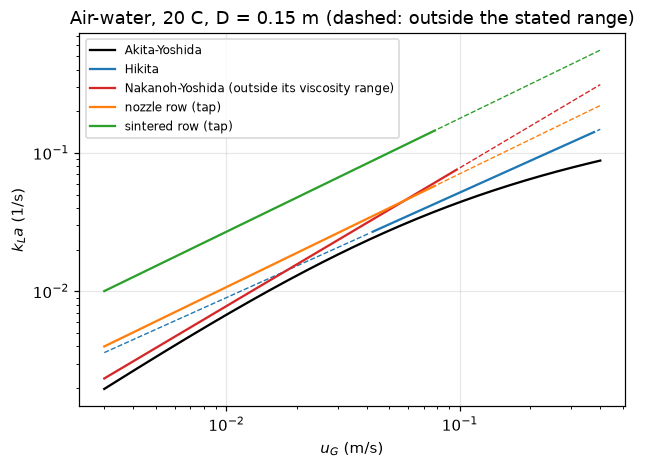

In [10]:
ug = np.geomspace(0.003, 0.4, 160)
L_, g_ = C.L, C.g
curves = {"Akita-Yoshida": ([kla_ay(u, D_T, L_, g_, K, C) for u in ug], K["ay_uG_min"], K["ay_uG_max"]),
          "Hikita": (kla_hikita(ug, L_, g_, K), K["hik_uG_min"], K["hik_uG_max"]),
          "Nakanoh-Yoshida (outside its viscosity range)": (kla_ny(ug, D_T, L_, g_, K, C), 0, K["ny_uG_max"]),
          "nozzle row (tap)": (kla_row(ug, K, "noz_tap"), K["noz_tap_uG_min"], K["noz_tap_uG_max"]),
          "sintered row (tap)": (kla_row(ug, K, "sin_tap"), K["sin_tap_uG_min"], K["sin_tap_uG_max"])}
fig, ax = plt.subplots(figsize=(6.4, 4.4))
for (lab, (y, lo, hi)), col in zip(curves.items(), ("k", "C0", "C3", "C1", "C2")):
    y = np.asarray(y)
    ins = (ug >= lo) & (ug <= hi)
    ax.loglog(ug, np.where(ins, y, np.nan), color=col, label=lab)
    ax.loglog(ug, np.where(ins, np.nan, y), color=col, ls="--", lw=0.9)
ax.set(xlabel="$u_G$ (m/s)", ylabel="$k_La$ (1/s)", title=f"Air-water, 20 C, D = {D_T} m (dashed: outside the stated range)")
ax.legend(fontsize=8)
plt.show()

### R2. How far below: Akita-Yoshida against the nozzle row and Hikita

The nozzle row is evaluated at its own diameter over the part of its range that
Akita-Yoshida covers; Hikita at the test diameter over its stated range. The largest
value of the ratio is the E7 maximum, or a window end when E6 = $n$ has no root in the
window. Akita-Yoshida has a diameter (E8) and Hikita has none, so the Hikita
comparison is repeated at other diameters.

In [11]:
say("Akita-Yoshida over the nozzle row at <<Dn:g>> m: <<lo:.3f>> at $u_G$ = <<l0:g>> m/s, <<hi:.3f>> at <<h0:g>> m/s, and "
    "at most <<mx:.4f>> at $u_G^*$ = <<us:.4f>> m/s ($\\varepsilon^*$ = <<es:.4f>>; `find_roots` on E6 = $n$ "
    "returns the same $u_G^*$ to <<gap:.1e>>). The smallest gap, $1 - $ <<mx:.3f>>, is <<g1:.2f>> times the "
    "row's printed mean error of <<err:g>> %; at the low end of the window it is <<g2:.2f>> times. Over Hikita "
    "at <<Dt:g>> m: <<hl:.3f>> at <<hl0:g>> m/s, <<hh:.3f>> at <<hh0:g>> m/s and at most <<hm:.4f>> at <<hu:.4f>> m/s "
    "(two routes agree to <<hg:.1e>>). So at these diameters Akita-Yoshida is below both over the whole window: by at least "
    "<<p1:pct1>> against the nozzle row and at least <<p2:pct1>> against Hikita. Hikita prints no mean error, "
    "so its gap has no printed scale.",
    lo=M["noz_ratio_lo"], hi=M["noz_ratio_hi"], mx=M["noz_max_ratio"], us=M["noz_uG_star"],
    es=M["noz_eps_star"], gap=M["noz_uG_star_root_gap"], g1=M["noz_gap_over_err"], err=K["noz_tap_err"],
    g2=M["noz_gap_lo_over_err"], hl=M["hik_ratio_lo"], hh=M["hik_ratio_hi"], hm=M["hik_max_ratio"],
    hu=M["hik_uG_star"], hg=M["hik_uG_star_root_gap"], p1=1 - M["noz_max_ratio"], p2=1 - M["hik_max_ratio"],
    Dn=K["noz_D"], l0=max(K["noz_tap_uG_min"], K["ay_uG_min"]), h0=K["noz_tap_uG_max"], Dt=D_T,
    hl0=K["hik_uG_min"], hh0=K["hik_uG_max"])
say("Hikita has no diameter and Akita-Yoshida's $k_La$ scales as $D^{<<e8:.2f>>}$ at fixed $u_G$ (E8), so the gap "
    "to Hikita depends on $D$. At Hikita's own diameters, <<d1:g>> and <<d2:g>> m, the largest ratio of "
    "Akita-Yoshida to Hikita is <<r1:.3f>> and <<r2:.3f>>. It reaches 1 at $D$ = <<dc:.4f>> m, the one root on <<s0:g>> to "
    "<<s1:g>> m of the maximum ratio minus one; that lies beyond Hikita's diameters and inside Akita-Yoshida's range of "
    "<<a0:g>> to <<a1:g>> m. At <<a1:g>> m, the largest diameter Akita-Yoshida states, it is up to <<r3:.4f>> times "
    "Hikita. The air viscosity is a page input (Parameters): Hikita's maximum ratio at <<m1:.2e>> and <<m2:.2e>> "
    "Pa s is <<q1:.3f>> and <<q2:.3f>>, against <<q0:.3f>> at the page's <<mu:.3g>> Pa s.",
    e8=M["e8_ay_D_exp"], d1=K["hik_D_min"], d2=K["hik_D_max"], r1=M["hik_max_ratio_hik_Dmin"],
    r2=M["hik_max_ratio_hik_Dmax"], dc=M["hik_cross_D"], s0=D_SCAN[0], s1=D_SCAN[1], a0=K["ay_D_min"],
    a1=K["ay_D_max"], r3=M["hik_max_ratio_ay_Dmax"], m1=MU_AIR_BRACKET[0], m2=MU_AIR_BRACKET[1],
    q1=M["hik_max_ratio_muG_lo"], q2=M["hik_max_ratio_muG_hi"], q0=M["hik_max_ratio"], mu=C.L.muG)

Akita-Yoshida over the nozzle row at 0.2 m: 0.518 at $u_G$ = 0.003 m/s, 0.682 at 0.08 m/s, and at most 0.7336 at $u_G^*$ = 0.0323 m/s ($\varepsilon^*$ = 0.0787; `find_roots` on E6 = $n$ returns the same $u_G^*$ to 1.5e-12). The smallest gap, $1 - $ 0.734, is 1.51 times the row's printed mean error of 17.7 %; at the low end of the window it is 2.72 times. Over Hikita at 0.15 m: 0.901 at 0.042 m/s, 0.605 at 0.38 m/s and at most 0.9020 at 0.0455 m/s (two routes agree to 1.7e-14). So at these diameters Akita-Yoshida is below both over the whole window: by at least 26.6 % against the nozzle row and at least 9.8 % against Hikita. Hikita prints no mean error, so its gap has no printed scale.

Hikita has no diameter and Akita-Yoshida's $k_La$ scales as $D^{0.17}$ at fixed $u_G$ (E8), so the gap to Hikita depends on $D$. At Hikita's own diameters, 0.1 and 0.19 m, the largest ratio of Akita-Yoshida to Hikita is 0.842 and 0.939. It reaches 1 at $D$ = 0.2752 m, the one root on 0.01 to 5 m of the maximum ratio minus one; that lies beyond Hikita's diameters and inside Akita-Yoshida's range of 0.152 to 0.6 m. At 0.6 m, the largest diameter Akita-Yoshida states, it is up to 1.1417 times Hikita. The air viscosity is a page input (Parameters): Hikita's maximum ratio at 1.70e-05 and 1.90e-05 Pa s is 0.916 and 0.891, against 0.902 at the page's 1.81e-05 Pa s.

### R3. The exponent of Akita-Yoshida against $n$ = 0.8

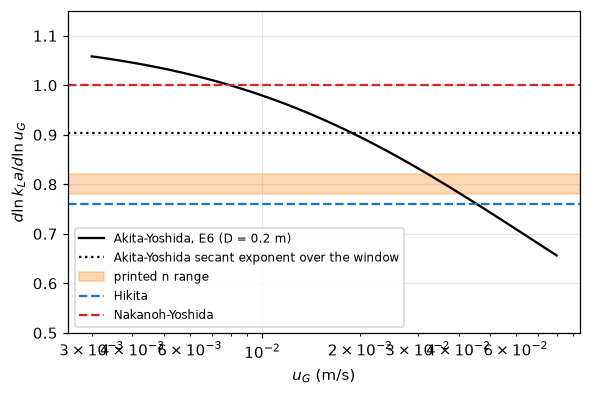

Over the nozzle window at 0.2 m the local exponent of Akita-Yoshida falls from 1.058 to 0.656; it equals 0.8 at $u_G$ = 0.0363 m/s. Its secant exponent over the window is 0.9038, 0.084 above the nozzle row's 0.82 and outside the printed range 0.78 to 0.82. Hikita's exponent is 0.76 and Nakanoh-Yoshida's 1 by construction (structural). The printed body supports $n$ near 0.8 for the $b\,u_G^n$ rows it fitted; Akita-Yoshida, the correlation it recommends, has no single exponent and averages 0.90 over the same window.

In [12]:
ugn = np.geomspace(0.003, 0.08, 120)
e6 = [slope_e6(holdup_ay(u, K["noz_D"], L_, g_, K, C), K) for u in ugn]
fig, ax = plt.subplots(figsize=(6.0, 3.8))
ax.semilogx(ugn, e6, "k", label=f"Akita-Yoshida, E6 (D = {K['noz_D']:g} m)")
ax.axhline(M["secant_exp_noz_window"], color="k", ls=":", label="Akita-Yoshida secant exponent over the window")
ax.axhspan(K["n_min_kastanek"], K["n_max_kastanek"], color="C1", alpha=0.3, label="printed n range")
ax.axhline(K["hik_e1"] - 1, color="C0", ls="--", label="Hikita")
ax.axhline(K["ny_fr_exp"], color="C3", ls="--", label="Nakanoh-Yoshida")
ax.set(xlabel="$u_G$ (m/s)", ylabel="$d\\ln k_La/d\\ln u_G$", ylim=(0.5, 1.15))
ax.legend(fontsize=8)
plt.show()
say("Over the nozzle window at 0.2 m the local exponent of Akita-Yoshida falls from <<a:.3f>> to <<b:.3f>>; "
    "it equals 0.8 at $u_G$ = <<c:.4f>> m/s. Its secant exponent over the window is <<s:.4f>>, "
    "<<d:.3f>> above the nozzle row's <<n:g>> and outside the printed range <<lo:g>> to <<hi:g>>. "
    "Hikita's exponent is <<h:g>> and Nakanoh-Yoshida's <<y:g>> by construction (structural). The printed "
    "body supports $n$ near 0.8 for the $b\\,u_G^n$ rows it fitted; Akita-Yoshida, the correlation it recommends, "
    "has no single exponent and averages <<s:.2f>> over the same window.",
    a=M["e6_noz_lo"], b=M["e6_noz_hi"], c=M["uG_e6_eq_0p8"], s=M["secant_exp_noz_window"],
    d=M["secant_minus_n_noz"], n=K["noz_tap_n"], lo=K["n_min_kastanek"], hi=K["n_max_kastanek"],
    h=round(K["hik_e1"] - 1, 2), y=K["ny_fr_exp"])

### R4. Figure 6-a.1: the held-out data and the liquid velocity

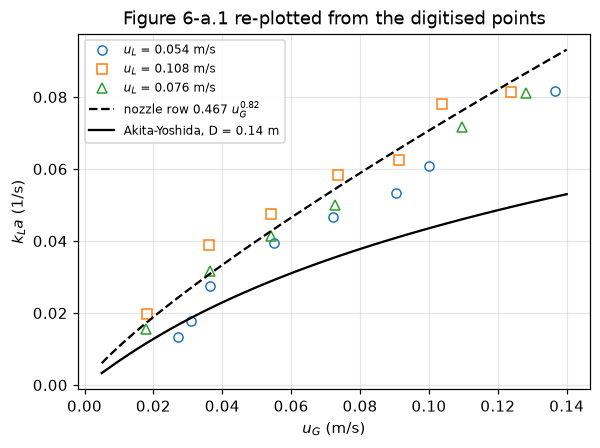

Against the drawn line the 21 markers have a geometric-mean ratio of 0.926 and a mean absolute deviation of 12.4 %, 0.70 times the row's printed mean error. Against Akita-Yoshida at 0.14 m (below its stated 0.152 m; the $D^{0.17}$ effect over that gap is 1.41 %) the geometric mean is 1.432, and 19 of the 21 markers lie above it (closest marker 5.2 % from it). Whether these liquid velocities are inside Akita-Yoshida's range depends on A4: 21 of 21 are above the 0.044 m/s of Table 2.1, 0 above the 0.44 m/s of Table 4-a.2.

In [13]:
d1 = C.f6a1[C.f6a1.kind == "marker"]
fig, ax = plt.subplots(figsize=(6.0, 4.2))
for (s, uL), mk in zip(d1.groupby(["series", "uL_m_s"]).groups, ("o", "s", "^")):
    dd = d1[d1.series == s]
    ax.plot(dd.uG_m_s, dd.kLa_1_s, mk, mfc="none", label=f"$u_L$ = {uL} m/s")
uu = np.linspace(0.005, 0.14, 100)
ax.plot(uu, kla_row(uu, K, "noz_tap"), "k--", label=f"nozzle row {K['noz_tap_b']:g} $u_G^{{{K['noz_tap_n']:g}}}$")
ax.plot(uu, [kla_ay(u, K["f6a1_D"], L_, g_, K, C) for u in uu], "k", label=f"Akita-Yoshida, D = {K['f6a1_D']:g} m")
ax.set(xlabel="$u_G$ (m/s)", ylabel="$k_La$ (1/s)", title="Figure 6-a.1 re-plotted from the digitised points")
ax.legend(fontsize=8)
plt.show()
say("Against the drawn line the <<n:d>> markers have a geometric-mean ratio of <<g:.3f>> and a mean absolute "
    "deviation of <<m:pct1>>, <<mr:.2f>> times the row's printed mean error. Against Akita-Yoshida at <<Df:g>> m "
    "(below its stated <<Dm:g>> m; the $D^{<<e8:.2f>>}$ effect over that gap is <<de:pct2>>) the geometric mean is "
    "<<ga:.3f>>, and <<na:d>> of the <<n:d>> markers lie above it (closest marker <<am:pct1>> from it). Whether "
    "these liquid velocities are inside Akita-Yoshida's range depends on A4: <<t1:d>> of <<n:d>> are above the "
    "<<u1:g>> m/s of Table 2.1, <<t2:d>> above the <<u2:g>> m/s of Table 4-a.2.",
    n=M["f1_n"], g=M["f1_geo_row"], m=M["f1_mad_row"], mr=M["f1_mad_row_over_err"],
    de=M["f1_ay_D_range_effect"] - 1, ga=M["f1_geo_ay"], na=M["f1_n_above_ay"], am=M["f1_n_above_ay__margin"],
    t1=M["f1_n_uL_above_t21"], t2=M["f1_n_uL_above_t4a2"], Df=K["f6a1_D"], Dm=K["ay_D_min"],
    e8=M["e8_ay_D_exp"], u1=K["ay_uL_max_t21"], u2=K["ay_uL_max_t4a2"])

In [14]:
UL = sorted(d1.uL_m_s.astype(float).unique())   # the liquid velocities of the figure, lowest first
UL_TAGS = {"ul_all": "all markers", "ul_le08": f"without the {M['f1_n_gt_08']} markers above uG {K['noz_tap_uG_max']:g} m/s",
           "ul_nofirst": "without each series' lowest-uG marker"}
tab = pd.DataFrame({lab: {
    **{f"mean ln(kLa/line), uL {u}": f"{M[f'{t}_mean_lr_uL{u}']:+.3f} ± {M[f'{t}_se_lr_uL{u}']:.3f}"
       for u in UL},
    f"difference uL {UL[-1]:g} - {UL[0]:g} (Welch)": f"{M[f'{t}_diff']:+.3f} ± {M[f'{t}_diff_se']:.3f}",
    "t": f"{M[f'{t}_diff_t']:.2f}",
    "slope of ln ratio on uL (s/m)": f"{M[f'{t}_slope']:+.2f} ± {M[f'{t}_slope_se']:.2f}"}
    for t, lab in UL_TAGS.items()})
display(tab)
say("The log ratio of measured $k_La$ to the drawn line rises with the liquid velocity. The highest and the lowest "
    "liquid velocity are compared at matched gas velocity: each marker of the $u_L$ = <<uh:g>> m/s series is paired with "
    "the marker of the $u_L$ = <<ul:g>> m/s series nearest in $u_G$ if that lies within <<tol:pct0>> of its $u_G$, each "
    "marker used once. At matched gas velocity the highest liquid velocity lies <<d:.3f>> ± <<ds:.3f>> above the "
    "lowest in log ratio to the drawn line (t = <<t:.2f>>, <<np:d>> pairs). The unmatched Welch comparison of all "
    "markers gives <<dw:.3f>> ± <<dws:.3f>> (t = <<tw:.2f>>); the matched value is the headline because the two series "
    "do not cover the same gas velocities. The slope of the log ratio on $u_L$ is <<s:.2f>> ± <<ss:.2f>> s/m. Without the "
    "markers above <<u8:g>> m/s the Welch difference is <<d2:.3f>> ± <<d2s:.3f>> (t = <<t2:.2f>>); without each series' "
    "lowest-$u_G$ marker it is <<d3:.3f>> ± <<d3s:.3f>> (t = <<t3:.2f>>). The figure the review cites for \"an influence "
    "of $u_L$ on $k_La$ can be neglected\" shows, in its own markers and at matched gas velocity, a difference of "
    "<<dp:pct0>> in $k_La$ between the highest and lowest liquid velocity, <<z:.1f>> standard errors from zero.",
    uh=UL[-1], ul=UL[0], tol=UL_PAIR_TOL, d=M["ul_pair_diff"], ds=M["ul_pair_se"], t=M["ul_pair_t"], np=M["ul_pair_n"],
    dw=M["ul_all_diff"], dws=M["ul_all_diff_se"], tw=M["ul_all_diff_t"], s=M["ul_all_slope"],
    ss=M["ul_all_slope_se"], u8=K["noz_tap_uG_max"], d2=M["ul_le08_diff"], d2s=M["ul_le08_diff_se"],
    t2=M["ul_le08_diff_t"], d3=M["ul_nofirst_diff"], d3s=M["ul_nofirst_diff_se"], t3=M["ul_nofirst_diff_t"],
    dp=math.exp(M["ul_pair_diff"]) - 1, z=M["ul_pair_t"])

,all markers,without the 8 markers above uG 0.08 m/s,without each series' lowest-uG marker
"mean ln(kLa/line), uL 0.054",-0.227 ± 0.064,-0.272 ± 0.100,-0.175 ± 0.044
"mean ln(kLa/line), uL 0.076",-0.052 ± 0.018,-0.047 ± 0.027,-0.044 ± 0.019
"mean ln(kLa/line), uL 0.108",+0.072 ± 0.037,+0.130 ± 0.037,+0.064 ± 0.042
difference uL 0.108 - 0.054 (Welch),+0.300 ± 0.074,+0.402 ± 0.107,+0.239 ± 0.061
t,4.06,3.77,3.95
slope of ln ratio on uL (s/m),+5.48 ± 1.22,+7.40 ± 1.82,+4.39 ± 0.98


The log ratio of measured $k_La$ to the drawn line rises with the liquid velocity. The highest and the lowest liquid velocity are compared at matched gas velocity: each marker of the $u_L$ = 0.108 m/s series is paired with the marker of the $u_L$ = 0.054 m/s series nearest in $u_G$ if that lies within 6 % of its $u_G$, each marker used once. At matched gas velocity the highest liquid velocity lies 0.222 ± 0.033 above the lowest in log ratio to the drawn line (t = 6.71, 5 pairs). The unmatched Welch comparison of all markers gives 0.300 ± 0.074 (t = 4.06); the matched value is the headline because the two series do not cover the same gas velocities. The slope of the log ratio on $u_L$ is 5.48 ± 1.22 s/m. Without the markers above 0.08 m/s the Welch difference is 0.402 ± 0.107 (t = 3.77); without each series' lowest-$u_G$ marker it is 0.239 ± 0.061 (t = 3.95). The figure the review cites for "an influence of $u_L$ on $k_La$ can be neglected" shows, in its own markers and at matched gas velocity, a difference of 25 % in $k_La$ between the highest and lowest liquid velocity, 6.7 standard errors from zero.

### R5. Figure 6-a.2: the markers over the drawn line

The abscissa of Figure 6-a.2 uses the measured holdup, not E1, so this tests E2
alone and is not the comparison of R2.

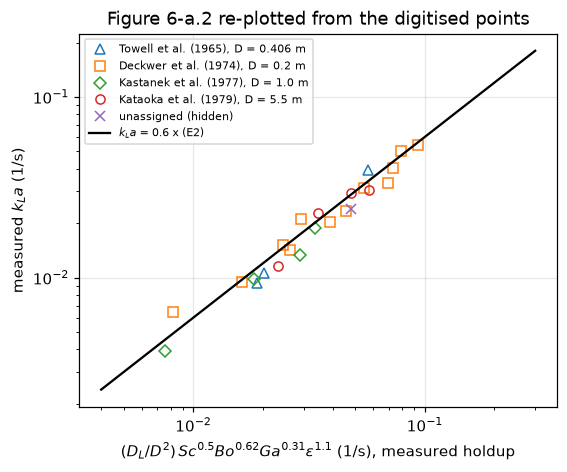

,triangle,square,diamond,circle
markers,3,12,4,4
geometric mean over line,0.942,0.979,0.864,0.954
s.e. of mean ln,0.102,0.041,0.039,0.065
above the line,1,4,0,2


Pooled, 7 of the 24 markers lie above the line (sign test, two-sided p = 0.064). For the Deckwer squares (0.20 m column) the geometric mean over the line is 0.979. To agree with R2, where Akita-Yoshida with its own holdup is 0.518 to 0.734 of the nozzle row fitted to the same laboratory's data (Table 4-a.1 cites Deckwer et al. 1974), the measured holdup would have to exceed the E1 holdup by a factor of 1.351 to 1.855. The review prints no holdup for these runs, so the page stops there. The marker nearest the line lies 2.2 % from it, against a reading error of 1.8 % (V4), so its side is not certain: with one marker more above the line the sign test gives p = 0.152, with one fewer p = 0.023.

In [15]:
d2 = C.f6a2[C.f6a2.kind == "marker"]
fig, ax = plt.subplots(figsize=(5.6, 4.4))
for m, mk in (("triangle", "^"), ("square", "s"), ("diamond", "D"), ("circle", "o"), ("unassigned", "x")):
    dd = d2[d2.marker == m]
    lab = f"{dd.author.iloc[0]}, D = {dd.Dc_m.iloc[0]} m" if m != "unassigned" else "unassigned (hidden)"
    ax.loglog(dd.x_group, dd.kLa_1_s, mk, mfc="none", label=lab)
xx = np.geomspace(4e-3, 0.3, 50)
ax.loglog(xx, K["ay_c2"] * xx, "k", label=f"$k_La$ = {K['ay_c2']:g} x (E2)")
ax.set(xlabel="$(D_L/D^2)\\,Sc^{0.5}Bo^{0.62}Ga^{0.31}\\varepsilon^{1.1}$ (1/s), measured holdup",
       ylabel="measured $k_La$ (1/s)", title="Figure 6-a.2 re-plotted from the digitised points")
ax.legend(fontsize=7)
plt.show()
display(pd.DataFrame({m: {"markers": M[f"f2_{m}_n"], "geometric mean over line": f"{M[f'f2_{m}_geo']:.3f}",
                          "s.e. of mean ln": f"{M[f'f2_{m}_se_log']:.3f}", "above the line": M[f"f2_{m}_above"]}
                      for m in ("triangle", "square", "diamond", "circle")}))
say("Pooled, <<k:d>> of the <<n:d>> markers lie above the line (sign test, two-sided p = <<p:.3f>>). For the "
    "Deckwer squares (0.20 m column) the geometric mean over the line is <<g:.3f>>. To agree with R2, where "
    "Akita-Yoshida with its own holdup is <<lo:.3f>> to <<mx:.3f>> of the nozzle row fitted to the same "
    "laboratory's data (Table 4-a.1 cites Deckwer et al. 1974), the measured holdup would have to exceed the E1 holdup by a factor of <<h1:.3f>> to "
    "<<h2:.3f>>. The review prints no holdup for these runs, so the page stops there. The marker nearest the line lies "
    "<<nd:pct1>> from it, against a reading error of <<re:pct1>> (V4), so its side is not certain: with one marker more "
    "above the line the sign test gives p = <<p2:.3f>>, with one fewer p = <<p1:.3f>>.",
    k=M["f2_n_above"], n=M["f2_n"], p=M["f2_sign_p"], g=M["f2_square_geo"], lo=M["noz_ratio_lo"],
    mx=M["noz_max_ratio"], h1=M["f2_holdup_ratio_at_max"], h2=M["f2_holdup_ratio_at_lo"],
    nd=M["f2_nearest_marker_dev"], re=10**M["v4_f2_sd_log10"] - 1, p1=M["f2_sign_p_one_fewer"], p2=M["f2_sign_p_one_more"])

### R6. The constant $b$ within Table 4-a.1

In [16]:
say("Sintered plates over nozzles, tap water: <<s:.3f>> at every $u_G$ (equal exponents). Salt solutions over "
    "tap water: <<a:.3f>> to <<b:.3f>> for the nozzle rows (at <<a0:g>> and <<b0:g>> m/s) and <<c:.3f>> to "
    "<<d:.3f>> for the sintered rows (at <<c0:g>> and <<d0:g>> m/s). These are ratios of printed constants; "
    "the review prints no salt-solution properties, so no salt row is set against Akita-Yoshida.",
    s=M["sin_over_noz_tap"], a=M["salt_over_tap_noz_lo"], b=M["salt_over_tap_noz_hi"],
    c=M["salt_over_tap_sin_lo"], d=M["salt_over_tap_sin_hi"], a0=K["noz_salt_uG_min"],
    b0=K["noz_salt_uG_max"], c0=K["sin_salt_uG_min"], d0=K["sin_salt_uG_max"])

Sintered plates over nozzles, tap water: 2.514 at every $u_G$ (equal exponents). Salt solutions over tap water: 1.162 to 1.063 for the nozzle rows (at 0.004 and 0.08 m/s) and 1.535 to 1.400 for the sintered rows (at 0.004 and 0.04 m/s). These are ratios of printed constants; the review prints no salt-solution properties, so no salt row is set against Akita-Yoshida.

## Validation

### V1. Reprint fidelity and the check values

In [17]:
say("<<a:d>> of the <<n:d>> Akita-Yoshida constants as the review prints them equal F1.1's transcription of the "
    "original papers. The page's functions reproduce all <<c:d>> check values of the second route, worst "
    "relative deviation <<w:.1e>>; among them F1.1's own test point at $\\nu_L = 1.005\\times10^{-6}$ m²/s.",
    a=M["v1_agree"], n=M["v1_pairs"], c=len(CHECK_DEV), w=max(abs(v) for v in CHECK_DEV.values()))

10 of the 10 Akita-Yoshida constants as the review prints them equal F1.1's transcription of the original papers. The page's functions reproduce all 53 check values of the second route, worst relative deviation 1.4e-11; among them F1.1's own test point at $\nu_L = 1.005\times10^{-6}$ m²/s.

### V2. Dimensional homogeneity

Each correlation is evaluated once in SI and once in cm-g-s at the same physical
condition. A dimensionless correlation returns the same $k_La$ (in 1/s) in both.

In [18]:
say("cm-g-s over SI, minus one: Akita-Yoshida <<a:.1e>>, Hikita <<h:.1e>>, Nakanoh-Yoshida with the root "
    "<<n:.1e>> (bound 1e-12). With the printed $u_G/(gD)$ the ratio is <<p:.4f>>: the printed group carries a "
    "unit of time per length, and its diameter exponent at fixed $u_G$ is <<pe:.3f>> instead of <<re:.3f>>. "
    "This is the evidence for A1.",
    a=M["v2_ay_cgs_gap"], h=M["v2_hik_cgs_gap"], n=M["v2_ny_cgs_gap"], p=M["v2_ny_printed_cgs_ratio"],
    pe=M["e8_ny_printed_D_exp"], re=M["e8_ny_D_exp"])

cm-g-s over SI, minus one: Akita-Yoshida 2.2e-16, Hikita 2.2e-16, Nakanoh-Yoshida with the root 0.0e+00 (bound 1e-12). With the printed $u_G/(gD)$ the ratio is 0.0100: the printed group carries a unit of time per length, and its diameter exponent at fixed $u_G$ is -0.330 instead of 0.170. This is the evidence for A1.

### V3. Analytic checks

E6 is $1.1\,(1-\varepsilon)/(1+3\varepsilon)$, which is 1.1 at $\varepsilon = 0$ in closed
form. At the test condition it is compared with a central difference of $\ln k_La$ in
$\ln u_G$ with step $h = 10^{-4}$: truncation is of order $h^2$ times the third
derivative (about $10^{-9}$) and round-off of order $10^{-16}/h$, so the gap is bounded
by $10^{-7}$. The diameter exponents of E8 are central differences in $\ln D$.

In [19]:
say("E6 at the test condition: <<e:.6f>>; the central difference differs by <<g:.1e>>. E7 by `find_roots` "
    "against the closed form: <<r1:.1e>> (nozzle) and <<r2:.1e>> (Hikita), relative. Diameter exponents at fixed "
    "$u_G$: holdup <<h:.1e>> (zero by E8), Akita-Yoshida <<a:.4f>>, Nakanoh-Yoshida <<n:.4f>> with the root and "
    "<<p:.4f>> as printed.",
    e=M["e6_T"], g=M["v3_e6_fd_gap"], r1=M["noz_uG_star_root_gap"], r2=M["hik_uG_star_root_gap"],
    h=M["e8_holdup_D_exp"], a=M["e8_ay_D_exp"], n=M["e8_ny_D_exp"], p=M["e8_ny_printed_D_exp"])

E6 at the test condition: 0.743003; the central difference differs by 2.8e-11. E7 by `find_roots` against the closed form: 1.5e-12 (nozzle) and 1.7e-14 (Hikita), relative. Diameter exponents at fixed $u_G$: holdup 0.0e+00 (zero by E8), Akita-Yoshida 0.1700, Nakanoh-Yoshida 0.1700 with the root and -0.3300 as printed.

### V4. The digitised lines against the formulas they draw

The scatter of these traces about the printed formulas is the reading error that the
R4 and R5 statistics carry.

In [20]:
say("Figure 6-a.1: the <<n1:d>> dash centres lie at <<g1:.4f>> times <<b:g>> $u_G^{<<nn:g>>}$ (geometric mean), "
    "standard deviation <<s1:pct1>> in the log, <<a1:.1e>> 1/s absolute. Figure 6-a.2: a log-log fit of the "
    "<<n2:d>> line points gives slope <<sl:.4f>> and intercept <<ic:.4f>> against 1 and <<c2:g>>; the points lie at "
    "<<g2:.4f>> times <<c2:g>> x, standard deviation <<s2:.4f>> decade (<<s2p:pct1>>). Both traces reproduce their "
    "printed formulas within about one reading error, so the axes need no correction. The matched R4 uL difference, "
    "<<d:.3f>> in the log, is <<dr:.1f>> times the per-point reading error.",
    n1=M["v4_f1_n"], g1=M["v4_f1_geo"], s1=M["v4_f1_sd_log"], a1=M["v4_f1_sd_abs"], n2=M["v4_f2_n"],
    sl=M["v4_f2_slope"], ic=M["v4_f2_intercept"], g2=M["v4_f2_geo"], s2=M["v4_f2_sd_log10"],
    s2p=10**M["v4_f2_sd_log10"] - 1, d=M["ul_pair_diff"], dr=M["ul_pair_diff"] / M["v4_f1_sd_log"],
    b=K["noz_tap_b"], nn=K["noz_tap_n"], c2=K["ay_c2"])

Figure 6-a.1: the 27 dash centres lie at 0.9980 times 0.467 $u_G^{0.82}$ (geometric mean), standard deviation 1.3 % in the log, 4.4e-04 1/s absolute. Figure 6-a.2: a log-log fit of the 25 line points gives slope 0.9876 and intercept 0.5693 against 1 and 0.6; the points lie at 0.9895 times 0.6 x, standard deviation 0.0078 decade (1.8 %). Both traces reproduce their printed formulas within about one reading error, so the axes need no correction. The matched R4 uL difference, 0.222 in the log, is 16.6 times the per-point reading error.

## Finding

The numbers above, set against the printed scatter.

In [21]:
say("**Conservative.** At the test diameter <<Dt:g>> m, Akita-Yoshida is the lowest of the counted printed air-water "
    "correlations everywhere in their common ranges (<<c:d>> of 3 above it throughout). Against the nozzle row at its "
    "own diameter <<Dn:g>> m, fitted to <<N:d>> points with a printed mean error of <<err:g>> %, it is lower by "
    "<<g1:pct0>> to <<g2:pct0>>: <<r1:.1f>> to <<r2:.1f>> mean errors. Against Hikita at <<Dt:g>> m the gap is "
    "<<h1:pct0>> to <<h2:pct0>>; Hikita has no diameter, and the ratio of Akita-Yoshida to Hikita reaches 1 at "
    "$D$ = <<dc:.3f>> m, beyond Hikita's own diameters, and <<r3:.2f>> at <<a1:g>> m. \"Conservative\" here means below "
    "the other printed correlations by these amounts, at the diameters named.\n\n"
    "**Exponent.** The fitted rows carry $n$ = <<nlo:g>> to <<nhi:g>>; Akita-Yoshida does not: its local exponent runs "
    "from <<ea:.2f>> to <<eb:.2f>> over the same window.\n\n"
    "**Liquid velocity.** The held-out Figure 6-a.1 does not support \"an influence of $u_L$ on $k_La$ can be "
    "neglected\" at the resolution of its own markers: at matched gas velocity the highest liquid velocity sits "
    "<<dp:pct0>> above the lowest in $k_La$, <<t:.1f>> standard errors (<<np:d>> pairs), <<de:.1f>> times the row's "
    "printed mean error of <<err:g>> %. The unmatched Welch difference of all markers keeps its sign without the "
    "high-$u_G$ markers (<<t2:.1f>>) and without the lowest-$u_G$ ones (<<t3:.1f>>). "
    "The page names no cause for it: the column, sparger and liquid velocities of Figure 6-a.1 all lie outside "
    "the row's basis. On the same markers Akita-Yoshida is low again: <<na:d>> of <<n:d>> lie above it "
    "(geometric mean <<ga:.2f>>).",
    c=M["r1_n_above"], N=int(K["noz_tap_N"]), err=K["noz_tap_err"], g1=1 - M["noz_max_ratio"],
    g2=1 - M["noz_ratio_lo"], r1=M["noz_gap_over_err"], r2=M["noz_gap_lo_over_err"],
    h1=1 - M["hik_max_ratio"], h2=1 - M["hik_ratio_hi"], ea=M["e6_noz_lo"], eb=M["e6_noz_hi"],
    dp=math.exp(M["ul_pair_diff"]) - 1, t=M["ul_pair_t"], np=M["ul_pair_n"], t2=M["ul_le08_diff_t"],
    t3=M["ul_nofirst_diff_t"], n=M["f1_n"], ga=M["f1_geo_ay"], na=M["f1_n_above_ay"],
    de=(math.exp(M["ul_pair_diff"]) - 1) / (K["noz_tap_err"] / 100), Dt=D_T, Dn=K["noz_D"], dc=M["hik_cross_D"],
    r3=M["hik_max_ratio_ay_Dmax"], a1=K["ay_D_max"], nlo=K["n_min_kastanek"], nhi=K["n_max_kastanek"])

**Conservative.** At the test diameter 0.15 m, Akita-Yoshida is the lowest of the counted printed air-water correlations everywhere in their common ranges (3 of 3 above it throughout). Against the nozzle row at its own diameter 0.2 m, fitted to 66 points with a printed mean error of 17.7 %, it is lower by 27 % to 48 %: 1.5 to 2.7 mean errors. Against Hikita at 0.15 m the gap is 10 % to 40 %; Hikita has no diameter, and the ratio of Akita-Yoshida to Hikita reaches 1 at $D$ = 0.275 m, beyond Hikita's own diameters, and 1.14 at 0.6 m. "Conservative" here means below the other printed correlations by these amounts, at the diameters named.

**Exponent.** The fitted rows carry $n$ = 0.78 to 0.82; Akita-Yoshida does not: its local exponent runs from 1.06 to 0.66 over the same window.

**Liquid velocity.** The held-out Figure 6-a.1 does not support "an influence of $u_L$ on $k_La$ can be neglected" at the resolution of its own markers: at matched gas velocity the highest liquid velocity sits 25 % above the lowest in $k_La$, 6.7 standard errors (5 pairs), 1.4 times the row's printed mean error of 17.7 %. The unmatched Welch difference of all markers keeps its sign without the high-$u_G$ markers (3.8) and without the lowest-$u_G$ ones (3.9). The page names no cause for it: the column, sparger and liquid velocities of Figure 6-a.1 all lie outside the row's basis. On the same markers Akita-Yoshida is low again: 19 of 21 lie above it (geometric mean 1.43).

## What pymrm adds

Nothing to the correlations: the page is algebra and calls no pymrm operator. pymrm
contributes `pymrm.checks.find_roots`, which solves the implicit holdup of E1 at every
point and finds the maxima of E7 as bracketed roots of E6 minus $n$ on the stated
windows, raising when the count is not what the algebra says, so the closed form has
a second route. What the page adds to the review is a set of checks it does not
print: its correlations set against each other in units of its own mean errors, the
dimensional check that exposes the printed Nakanoh-Yoshida group, and the scatter of
its two kLa figures as numbers.

## Reuse

- `holdup_ay`, `kla_ay`, `kla_hikita`, `kla_ny` and `kla_row` take SI arguments and the
  dictionary `K`, and can be lifted into a reactor model as mass-transfer closures.
  Use `kla_ny` only with the root restored and only inside its viscosity range.
- Choosing Akita-Yoshida over the nozzle or sintered rows is a choice of a lower
  $k_La$ by the factors in R1 and R2, at the diameters named below; state it as such.
- For a column with liquid flow, Figure 6-a.1 is the only evidence the review prints;
  read R4 before assuming $u_L$ has no effect.
- The Akita-Yoshida liquid-velocity range is uncertain by a factor of ten (A4).
- Related pages: [F1.1](../F1.1-akita-yoshida-bubble-column/) (Akita-Yoshida against
  its own papers), [F1.3](../F1.3-wilkinson-high-pressure-holdup/) and
  [F1.4](../F1.4-krishna-ellenberger-holdup/) (holdup).

In [22]:
say("**Diameters.** R1 sets the correlations against Akita-Yoshida at the test diameter <<Dt:g>> m, R2 the nozzle row "
    "at its own <<Dn:g>> m and Hikita at <<Dt:g>> m. Akita-Yoshida has a diameter and Hikita none: the gap to Hikita "
    "closes at $D$ = <<dc:.3f>> m, and at <<a1:g>> m, the largest diameter Akita-Yoshida states, it is up to "
    "<<r3:.2f>> times Hikita. Read the factors above at the diameter of the column in hand.",
    Dt=D_T, Dn=K["noz_D"], dc=M["hik_cross_D"], a1=K["ay_D_max"], r3=M["hik_max_ratio_ay_Dmax"])

**Diameters.** R1 sets the correlations against Akita-Yoshida at the test diameter 0.15 m, R2 the nozzle row at its own 0.2 m and Hikita at 0.15 m. Akita-Yoshida has a diameter and Hikita none: the gap to Hikita closes at $D$ = 0.275 m, and at 0.6 m, the largest diameter Akita-Yoshida states, it is up to 1.14 times Hikita. Read the factors above at the diameter of the column in hand.

### The break table

Every non-structural number registered below has a row that moves it. Each row
mistypes one printed constant (by 10 %, `hik_e1` by 5 %: at 10 % the Hikita
ratio to Akita-Yoshida leaves the stop rule's window), or changes one input or data point, and reruns the
whole study; the claims it fails are counted. Mistyped by 10 %, four window ends
bind no reported number and get no row: `ny_uG_max`, `noz_tap_uG_min`,
`sin_tap_uG_min` and `sin_tap_uG_max` (each minimum of R1 sits at an interior root
or at the end of Akita-Yoshida's range); the two A4 limits get rows that cross a
liquid velocity of Figure 6-a.1. The maxima of R2 are taken over the window ends and
the interior roots of E6 = n, so a defect that removes the interior maximum moves
the reported maximum instead of stopping the study. A row under which a stop rule
fires still makes the study raise; such a row records a crash, and the summary below
lists every row that only crashes, which is not counted as catching a claim. The
controls fail nothing.

In [23]:
RTOL = 1e-6
STRUCTURAL = {"v2_hik_cgs_gap": "the four groups of E3 are dimensionless and its prefactor g/uG is 1/s for any exponents",
              "v3_e6_fd_gap": "E6 is the exact derivative of E2 with E1 for any printed constants; bound: truncation plus round-off",
              "noz_uG_star_root_gap": "E7 closed form is the exact root of E6 = n; bound: find_roots xtol",
              "hik_uG_star_root_gap": "E7 closed form is the exact root of E6 = n; bound: find_roots xtol",
              "f2_triangle_n": "marker count from the legend shapes", "f2_diamond_n": "marker count from the legend shapes",
              "f2_circle_n": "marker count from the legend shapes", "f2_square_n": "marker count from the legend shapes",
              "f2_n": "digitised marker count", "f1_n": "digitised marker count", "v4_f1_n": "digitised dash count",
              "v4_f2_n": "digitised line points", "v1_pairs": "number of constants compared"}
BOUNDS = {"v2_ay_cgs_gap": (1e-12, "identity", "E1 and E2 are dimensionless with uG/sqrt(gD)"),
          "v2_ny_cgs_gap": (1e-12, "identity", "E4 is dimensionless with the root restored"),
          "e8_holdup_D_exp": (1e-9, "identity", "2/8 + 3/12 - 1/2 = 0; central difference of a root solved to 1e-15"),
          "v3_e6_fd_gap": (1e-7, "theory", STRUCTURAL["v3_e6_fd_gap"]),
          "noz_uG_star_root_gap": (1e-8, "tolerance", STRUCTURAL["noz_uG_star_root_gap"]),
          "hik_uG_star_root_gap": (1e-8, "tolerance", STRUCTURAL["hik_uG_star_root_gap"]),
          "v2_hik_cgs_gap": (1e-12, "identity", STRUCTURAL["v2_hik_cgs_gap"])}
# Count margins: at least the reading error of a marker (V4: about 1.3 % on Figure
# 6-a.1 and 1.8 % on Figure 6-a.2).
COUNTS = {"ul_pair_n": 0.013, "r1_n_above": 0.05, "f1_n_above_ay": 0.03, "f1_n_uL_above_t21": 0.05, "f1_n_uL_above_t4a2": 0.05,
          "f2_triangle_above": 0.02, "f2_square_above": 0.02, "f2_diamond_above": 0.02,
          "f2_circle_above": 0.02, "f2_n_above": 0.02}
EXACT = {"v1_agree", "f1_n_gt_08"}
SKIP = set()


def register(M):
    """Register every reported number with its kind."""
    for name, v in M.items():
        if name.startswith("_") or name.endswith("__margin") or name in SKIP:
            continue
        if name in BOUNDS:
            mx, basis, note = BOUNDS[name]
            claims.bound(name, v, max=mx, basis=basis, structural=name in STRUCTURAL, note=note)
        elif name in STRUCTURAL:
            claims.exact(name, v, structural=True, note=STRUCTURAL[name])
        elif name in COUNTS:
            claims.exact(name, v, margin=M[name + "__margin"], min_margin=COUNTS[name])
        elif name in EXACT:
            claims.exact(name, v)
        else:
            claims.value(name, v, rtol=RTOL)


register(M)

In [24]:
UNUSED = {"ay_uG_max", "ay_Ht_min_t21", "ay_Ht_max_t21", "ay_Ht_min_t4a2", "ay_Ht_max_t4a2",
          "ay_muL_min", "ay_muL_max", "hik_muL_min", "ny_muL_max", "noz_salt_N",
          "noz_salt_err", "sin_tap_N", "sin_tap_err", "sin_salt_N", "sin_salt_err", "noz_uL_min",
          "noz_uL_max", "f6a1_Ht", "f6a1_T_C", "f6a2_Dc_large", "n_min_kastanek", "n_max_kastanek", "noz_tap_N"}
# Window ends that bind no reported number (each minimum sits at an interior root or
# at another range's end), and the two A4 limits, which get rows of their own below.
NONBINDING = {"ny_uG_max", "noz_tap_uG_min", "sin_tap_uG_min", "sin_tap_uG_max", "ay_uL_max_t21", "ay_uL_max_t4a2"}


def set_to(name, v):
    return f"{name} {PRINTED[name]} -> {v:g}", {**K, name: v}, C


def mistyped(name):
    v = K[name] * 1.1 if K[name] != 0 else 0.1
    return f"{name} {PRINTED[name]} -> {v:.6g}", {**K, name: v}, C


def liquid(field, f):
    return f"water {field} x {f:g}", K, replace(C, L=replace(C.L, **{field: getattr(C.L, field) * f}))


def fig_change(fig, i, col, f):
    df = getattr(C, fig).copy()
    df.loc[i, col] = df.loc[i, col] * f
    return f"{fig} row {i} {col} x {f:g}", K, replace(C, **{fig: df})


def fig_relabel(fig, i, col, new):
    df = getattr(C, fig).copy()
    old = df.loc[i, col]
    df.loc[i, col] = new
    return f"{fig} row {i} {col} {old} -> {new}", K, replace(C, **{fig: df})


def fig_drop(fig, i):
    return f"{fig} row {i} dropped", K, replace(C, **{fig: getattr(C, fig).drop(index=i).reset_index(drop=True)})


# hik_e1 is mistyped by 5 %: by 10 % the Hikita ratio to A-Y leaves the stop rule's window
# and the row would only stop the study.
DEFECTS = [mistyped(k) for k in K if k not in UNUSED | NONBINDING | {"hik_e1"}] + [
    set_to("hik_e1", K["hik_e1"] * 1.05),
    set_to("ay_uL_max_t21", 0.06), set_to("ay_uL_max_t4a2", 0.06),
    ("gravity 9.81 -> 9.7", K, replace(C, g=9.7)),
    liquid("rho", 1.02), liquid("mu", 1.05), liquid("sigma", 1.05), liquid("DL", 1.05), liquid("muG", 1.1),
    ("E1 Froude group without the root", K, replace(C, ay_fr_root=False)),
    ("E4 Froude group as printed, uG/(gD)", K, replace(C, ny_fr_root=False)),
    ("test diameter 0.15 -> 0.16 m", K, replace(C, D_T=0.16)),
    ("test velocity 0.05 -> 0.055 m/s", K, replace(C, uG_T=0.055)),
    fig_change("f6a1", 0, "kLa_1_s", 1.05), fig_change("f6a1", 10, "uG_m_s", 1.05),
    fig_change("f6a1", 4, "uG_m_s", 1.15),
    fig_change("f6a1", 17, "kLa_1_s", 0.95), fig_drop("f6a1", 8),
    fig_relabel("f6a1", 20, "uL_m_s", "0.054"), fig_change("f6a1", 25, "kLa_1_s", 1.03),
    fig_change("f6a2", 1, "kLa_1_s", 1.05), fig_change("f6a2", 0, "x_group", 1.05),
    fig_change("f6a2", 5, "kLa_1_s", 0.95), fig_change("f6a2", 16, "kLa_1_s", 1.05),
    fig_change("f6a2", 5, "kLa_1_s", 1.2), fig_change("f6a2", 11, "kLa_1_s", 1.12),
    fig_relabel("f6a2", 6, "marker", "square"), fig_change("f6a2", 30, "kLa_1_s", 1.02),
    fig_drop("f6a2", 15),
]
CONTROLS = [("control: clean rerun", K, C),
            ("control: Figure 6-a.1 rows in reverse order", K, replace(C, f6a1=C.f6a1.iloc[::-1].reset_index(drop=True)))]
claims.define_rows([r_ for r_, _, _ in CONTROLS + DEFECTS])
BREAK, CRASH = [], set()   # CRASH: rows under which every claim came back without a number
for row, k_, c_ in CONTROLS + DEFECTS:
    try:
        Mb = study(k_, c_)
    except ValueError:
        Mb = {}
    for name in claims.metrics:
        BREAK.append((row, name, claims.breaks(row, name, Mb.get(name, np.nan))))
    if not any(name in Mb for name in claims.metrics):
        CRASH.add(row)

In [25]:
# The break table: one line per row, with the claims it fails.
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<60} {'claims failed':>13}")
for r_, cs in by_row.items():
    print(f"{r_[:60]:<60} {sum(cs):13d}")
_caught = {m_ for r_, m_, c_ in BREAK if c_ and r_ not in CRASH}   # a crash is not a moved claim
print(f"rows that only crash: {', '.join(sorted(CRASH)) or 'none'}")
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught
               and not claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; open: {', '.join(_open) or 'none'}")

injected defect                                              claims failed
control: clean rerun                                                     0
control: Figure 6-a.1 rows in reverse order                              0
ay_C 0.2 -> 0.22                                                        38
ay_C_electrolyte 0.25 -> 0.275                                           1
ay_holdup_power 4 -> 4.4                                                39
ay_a_Bo 1/8 -> 0.1375                                                   41
ay_b_Ga 1/12 -> 0.0916667                                               42
ay_c2 0.6 -> 0.66                                                       38
ay_sc_exp 0.5 -> 0.55                                                   30
ay_p_Bo 0.62 -> 0.682                                                   32
ay_q_Ga 0.31 -> 0.341                                                   32
ay_eps_exp 1.1 -> 1.21                                                  38
ay_uG_min 0.003 -> 0.0033

In [26]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for F1.8:
  kla_ay_T                   = 0.027509         value  rtol 1e-06
  eps_ay_T                   = 0.10724          value  rtol 1e-06
  ratio_hikita_over_ay_T     = 1.1095           value  rtol 1e-06
  kla_hikita_T               = 0.030522         value  rtol 1e-06
  min_ratio_hikita_over_ay   = 1.1086           value  rtol 1e-06
  ratio_ny_over_ay_T         = 1.4172           value  rtol 1e-06
  kla_ny_T                   = 0.038987         value  rtol 1e-06
  min_ratio_ny_over_ay       = 1.1524           value  rtol 1e-06
  ratio_noz_tap_over_ay_T    = 1.4555           value  rtol 1e-06
  kla_noz_tap_T              = 0.040038         value  rtol 1e-06
  min_ratio_noz_tap_over_ay  = 1.4315           value  rtol 1e-06
  ratio_sin_tap_over_ay_T    = 3.6589           value  rtol 1e-06
  kla_sin_tap_T              = 0.10065          value  rtol 1e-06
  min_ratio_sin_tap_over_ay  = 3.5988           value  rtol 1e-06
  mu_water_over_ny_muL_min   = 0.201            value  rtol